# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  879M    0  879M    0     0  13.0M      0 --:--:--  0:01:07 --:--:-- 18.0M


In [2]:
!rm SUSY.csv

rm: SUSY.csv: No such file or directory


In [3]:
!gunzip SUSY.csv.gz

In [4]:
ls -lh

total 5178096
-rw-r--r--  1 han  staff   4.5M Oct 23 16:36 Lab.7.ipynb
-rw-r--r--  1 han  staff   149K Oct  9 19:27 Lab.7.pdf
-rw-r--r--  1 han  staff   228M Oct 23 16:30 SUSY-small.csv
-rw-r--r--  1 han  staff   2.2G Oct 23 16:38 SUSY.csv


The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

total 5178096
-rw-r--r--  1 han  staff   4.5M Oct 23 16:36 Lab.7.ipynb
-rw-r--r--  1 han  staff   149K Oct  9 19:27 Lab.7.pdf
-rw-r--r--  1 han  staff   228M Oct 23 16:30 SUSY-small.csv
-rw-r--r--  1 han  staff   2.2G Oct 23 16:38 SUSY.csv


We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

total 5178096
-rw-r--r--  1 han  staff   4.5M Oct 23 16:36 Lab.7.ipynb
-rw-r--r--  1 han  staff   149K Oct  9 19:27 Lab.7.pdf
-rw-r--r--  1 han  staff   228M Oct 23 16:38 SUSY-small.csv
-rw-r--r--  1 han  staff   2.2G Oct 23 16:38 SUSY.csv


In [10]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [11]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [13]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['S_R',
 'MET_rel',
 'axial_MET',
 'M_Delta_R',
 'R',
 'dPhi_r_b',
 'M_TR_2',
 'cos_theta_r1',
 'M_R',
 'MT2']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [16]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [17]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [18]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


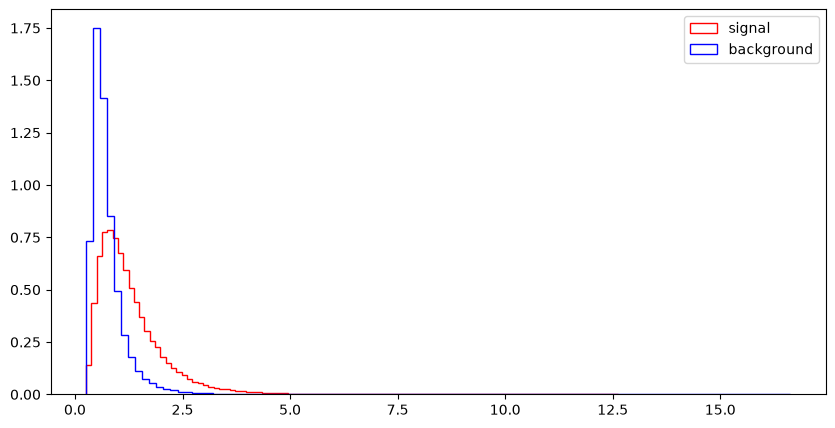

l_1_eta


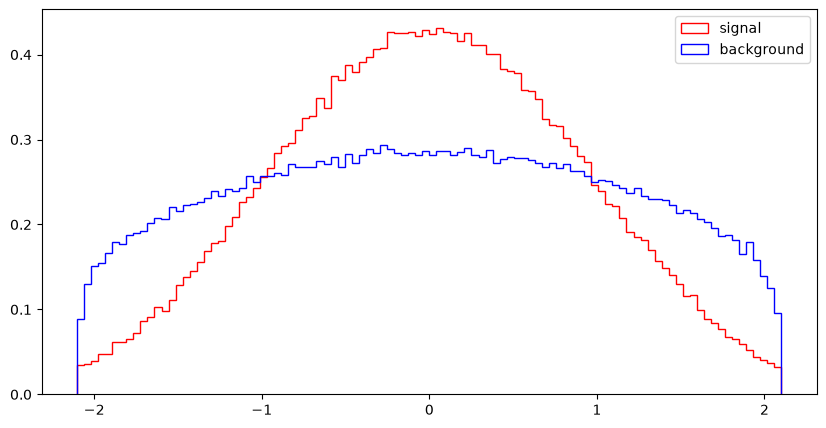

l_1_phi


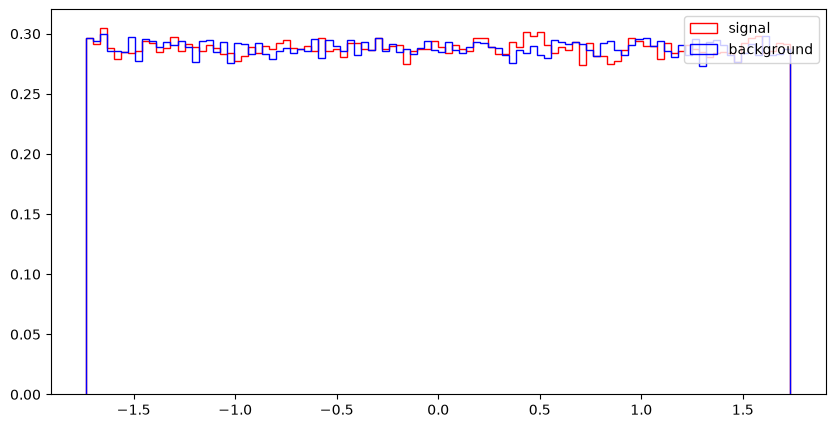

l_2_pT


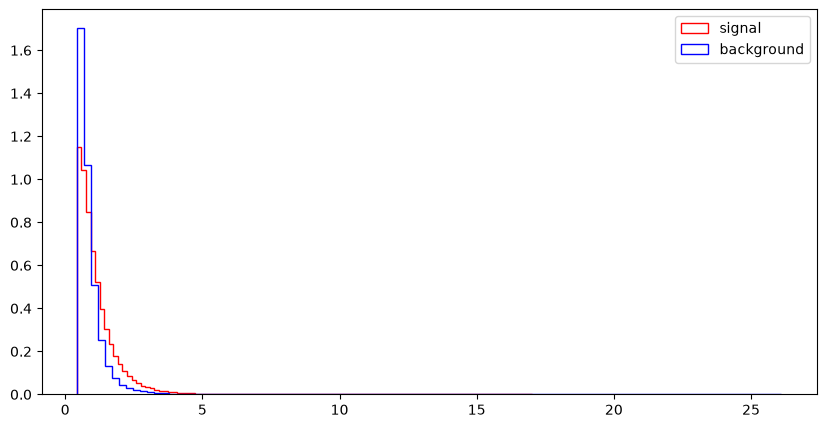

l_2_eta


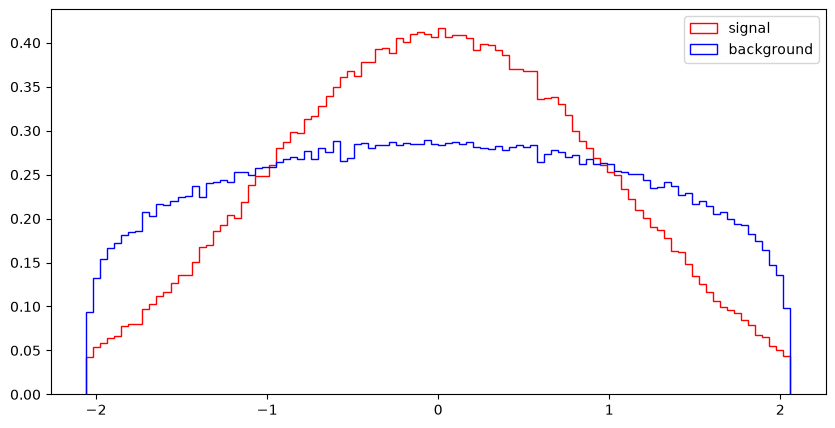

l_2_phi


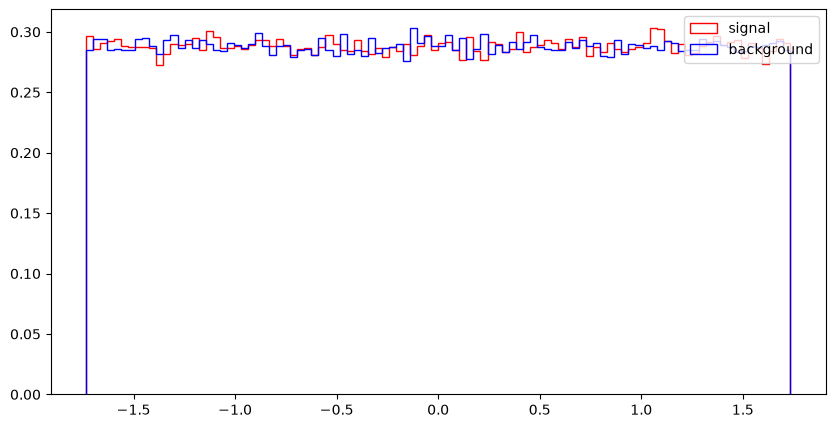

MET


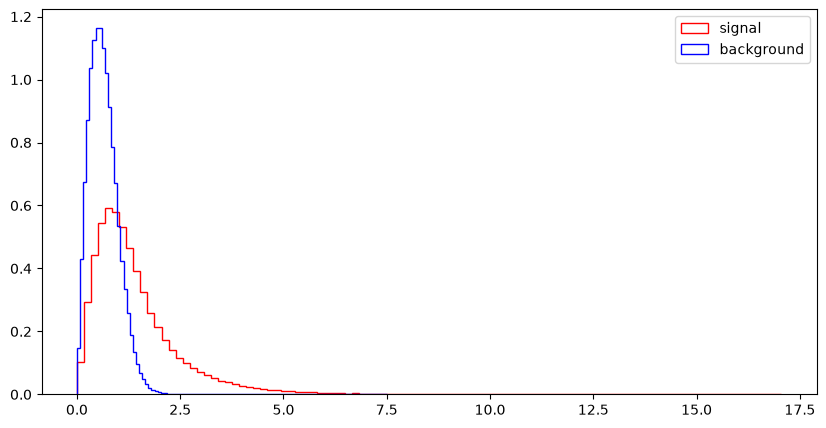

MET_phi


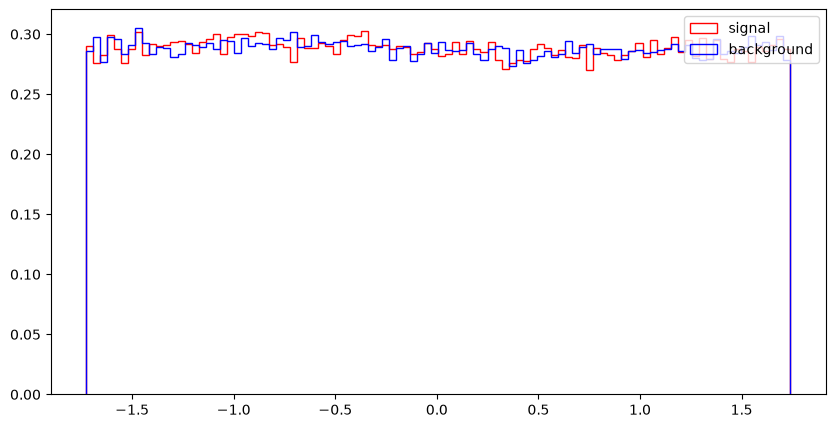

MET_rel


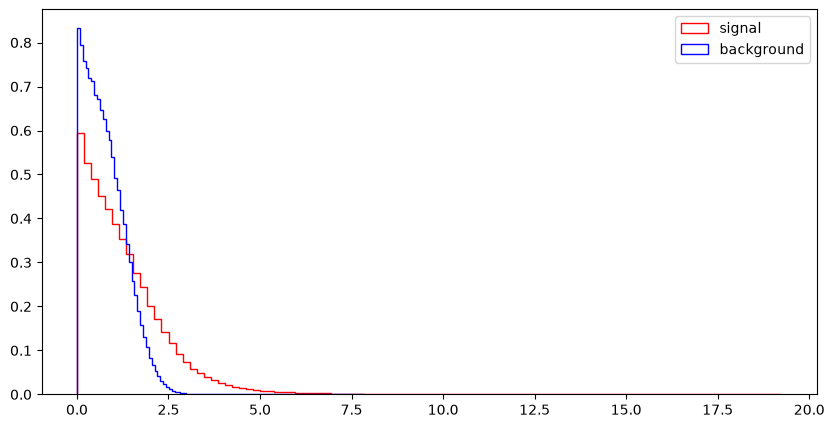

axial_MET


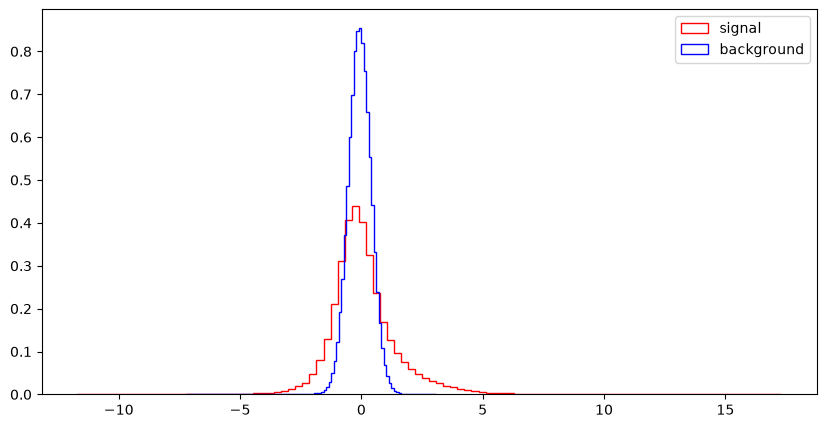

M_R


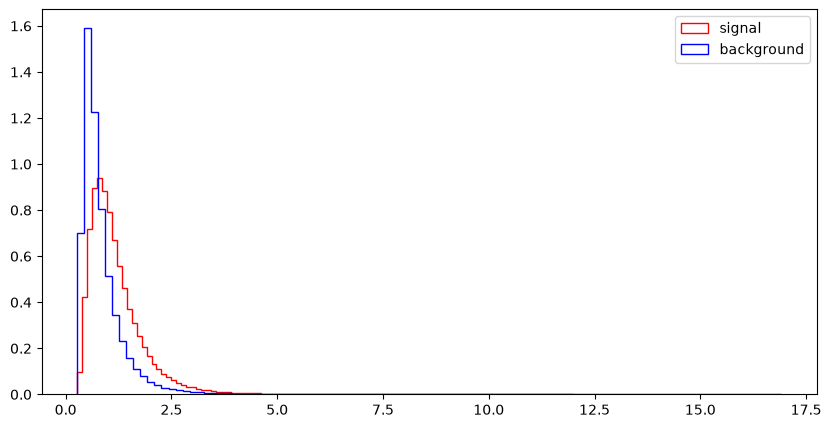

M_TR_2


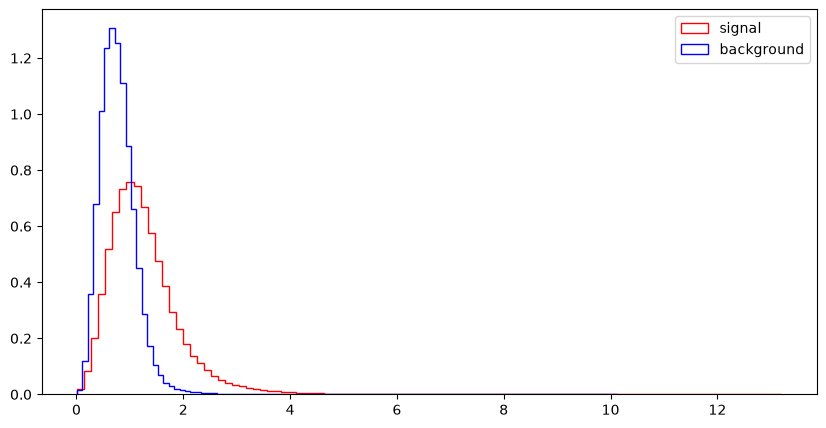

R


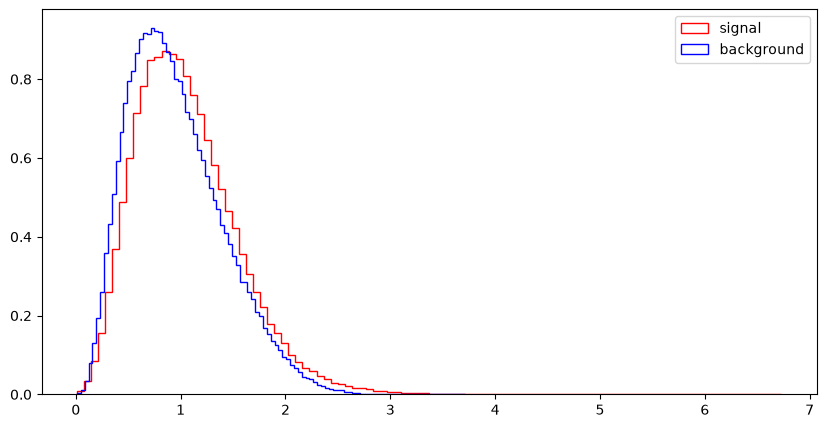

MT2


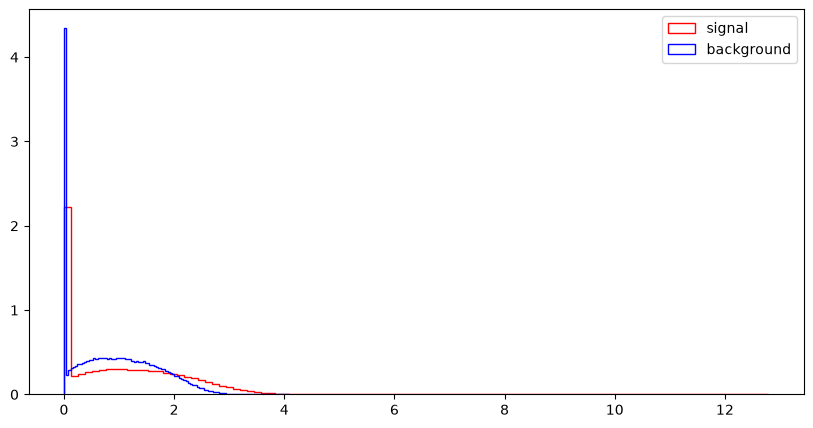

S_R


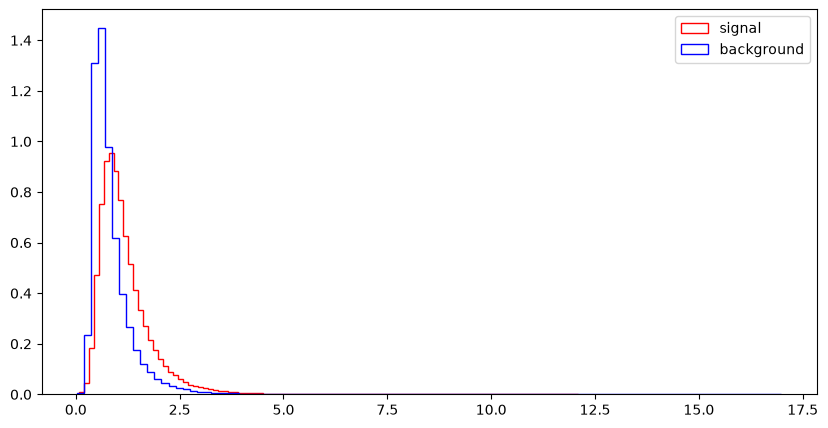

M_Delta_R


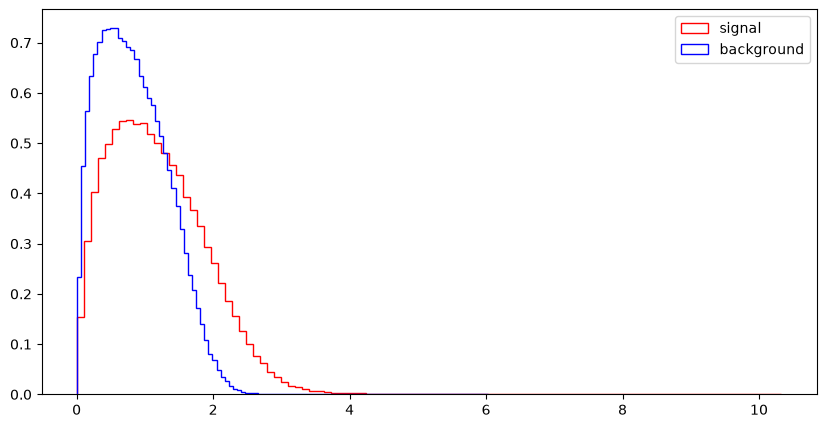

dPhi_r_b


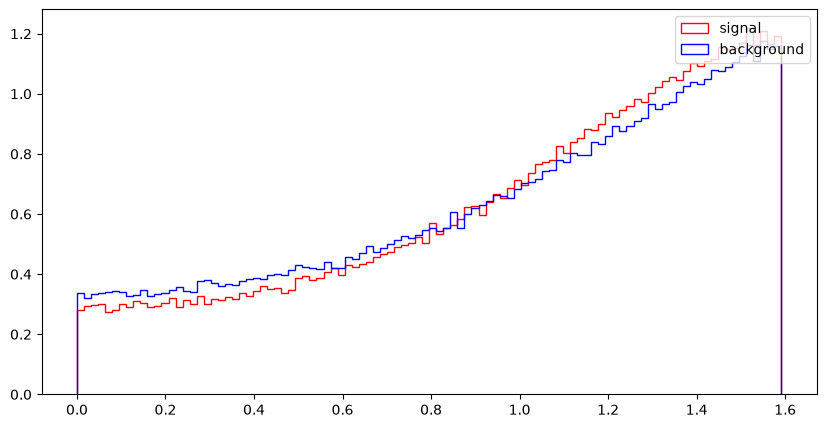

cos_theta_r1


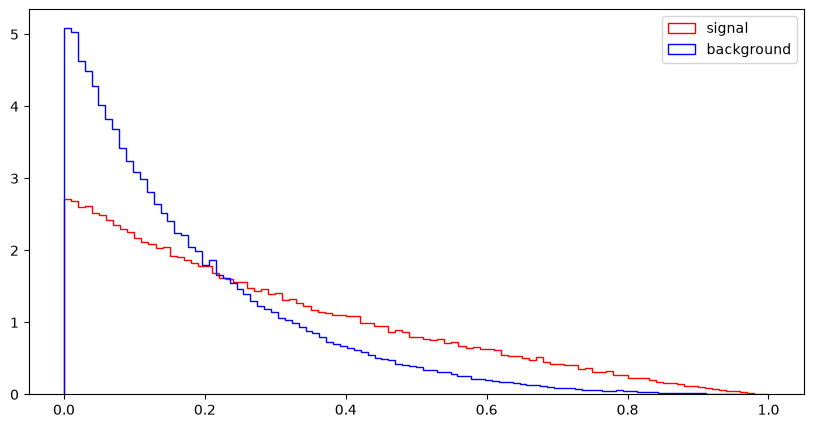

In [19]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

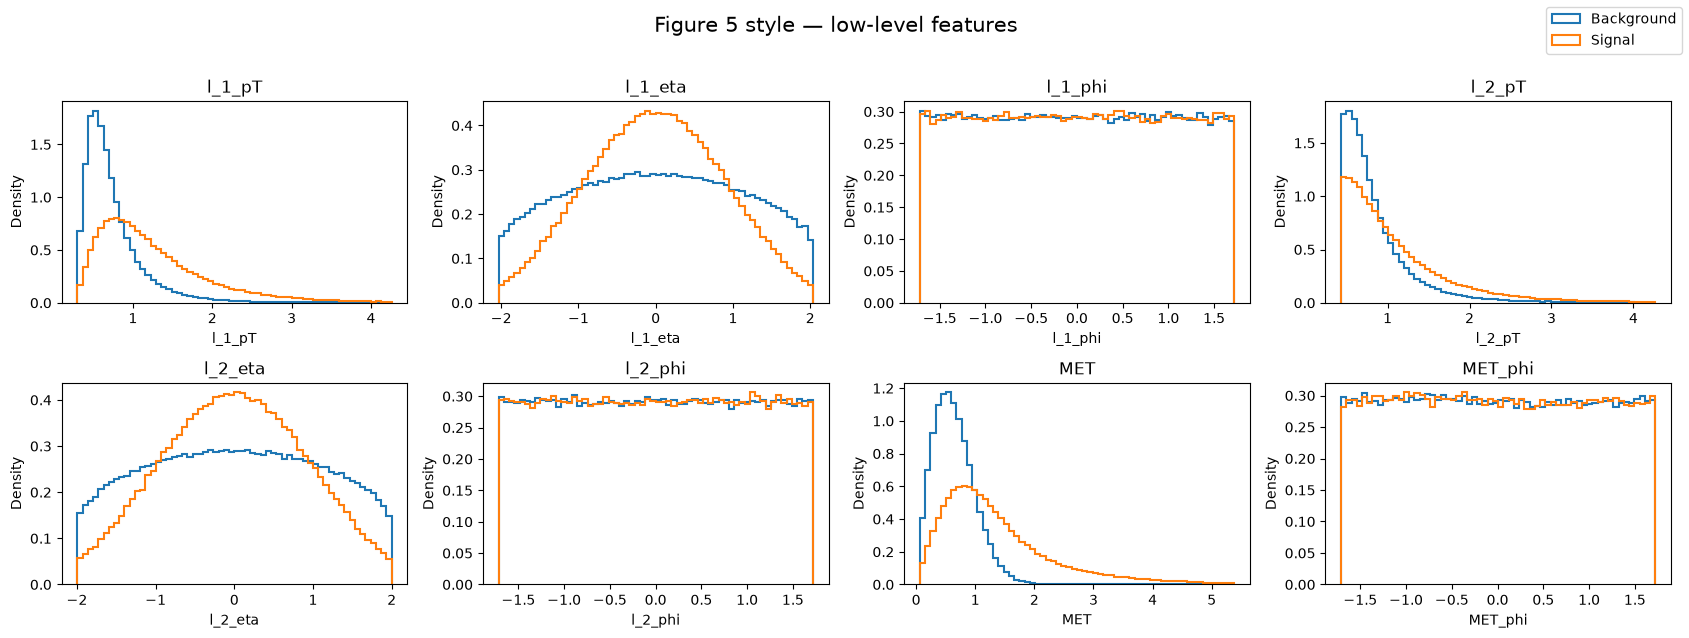

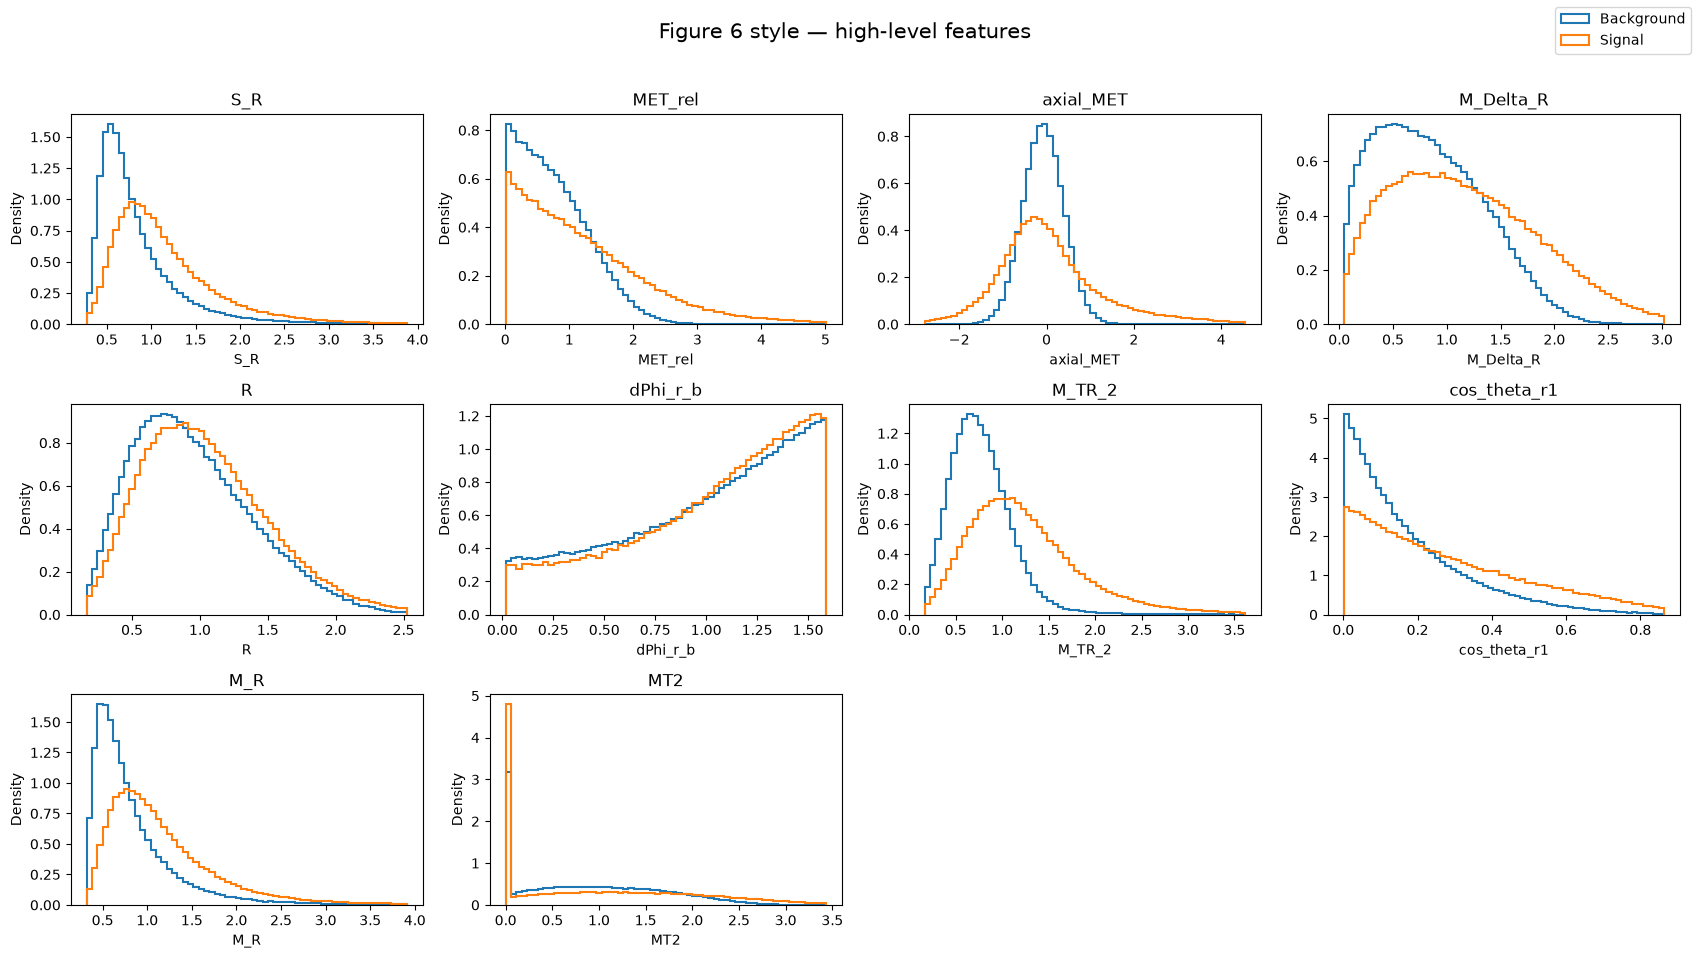

In [20]:
def plot_feature_grid(columns, title, bins=60):
    ncols=4; nrows=int(np.ceil(len(columns)/ncols))
    fig,axes=plt.subplots(nrows,ncols,figsize=(17,3.2*nrows))
    axes=np.asarray(axes).ravel()
    for ax,col in zip(axes,columns):
        s=df_sig[col].to_numpy(); b=df_bkg[col].to_numpy()
        lo,hi=np.percentile(df[col],[0.5,99.5])
        edges=np.linspace(lo,hi,bins+1)
        ax.hist(b,bins=edges,density=True,histtype='step',lw=1.5,label='Background')
        ax.hist(s,bins=edges,density=True,histtype='step',lw=1.5,label='Signal')
        ax.set_title(col);ax.set_xlabel(col);ax.set_ylabel('Density')
    for ax in axes[len(columns):]:ax.axis('off')
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper right')
    fig.suptitle(title,fontsize=15);fig.tight_layout(rect=[0,0,1,.96]);plt.show()
plot_feature_grid(RawNames,'Figure 5 style — low-level features')
plot_feature_grid(FeatureNames,'Figure 6 style — high-level features')

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

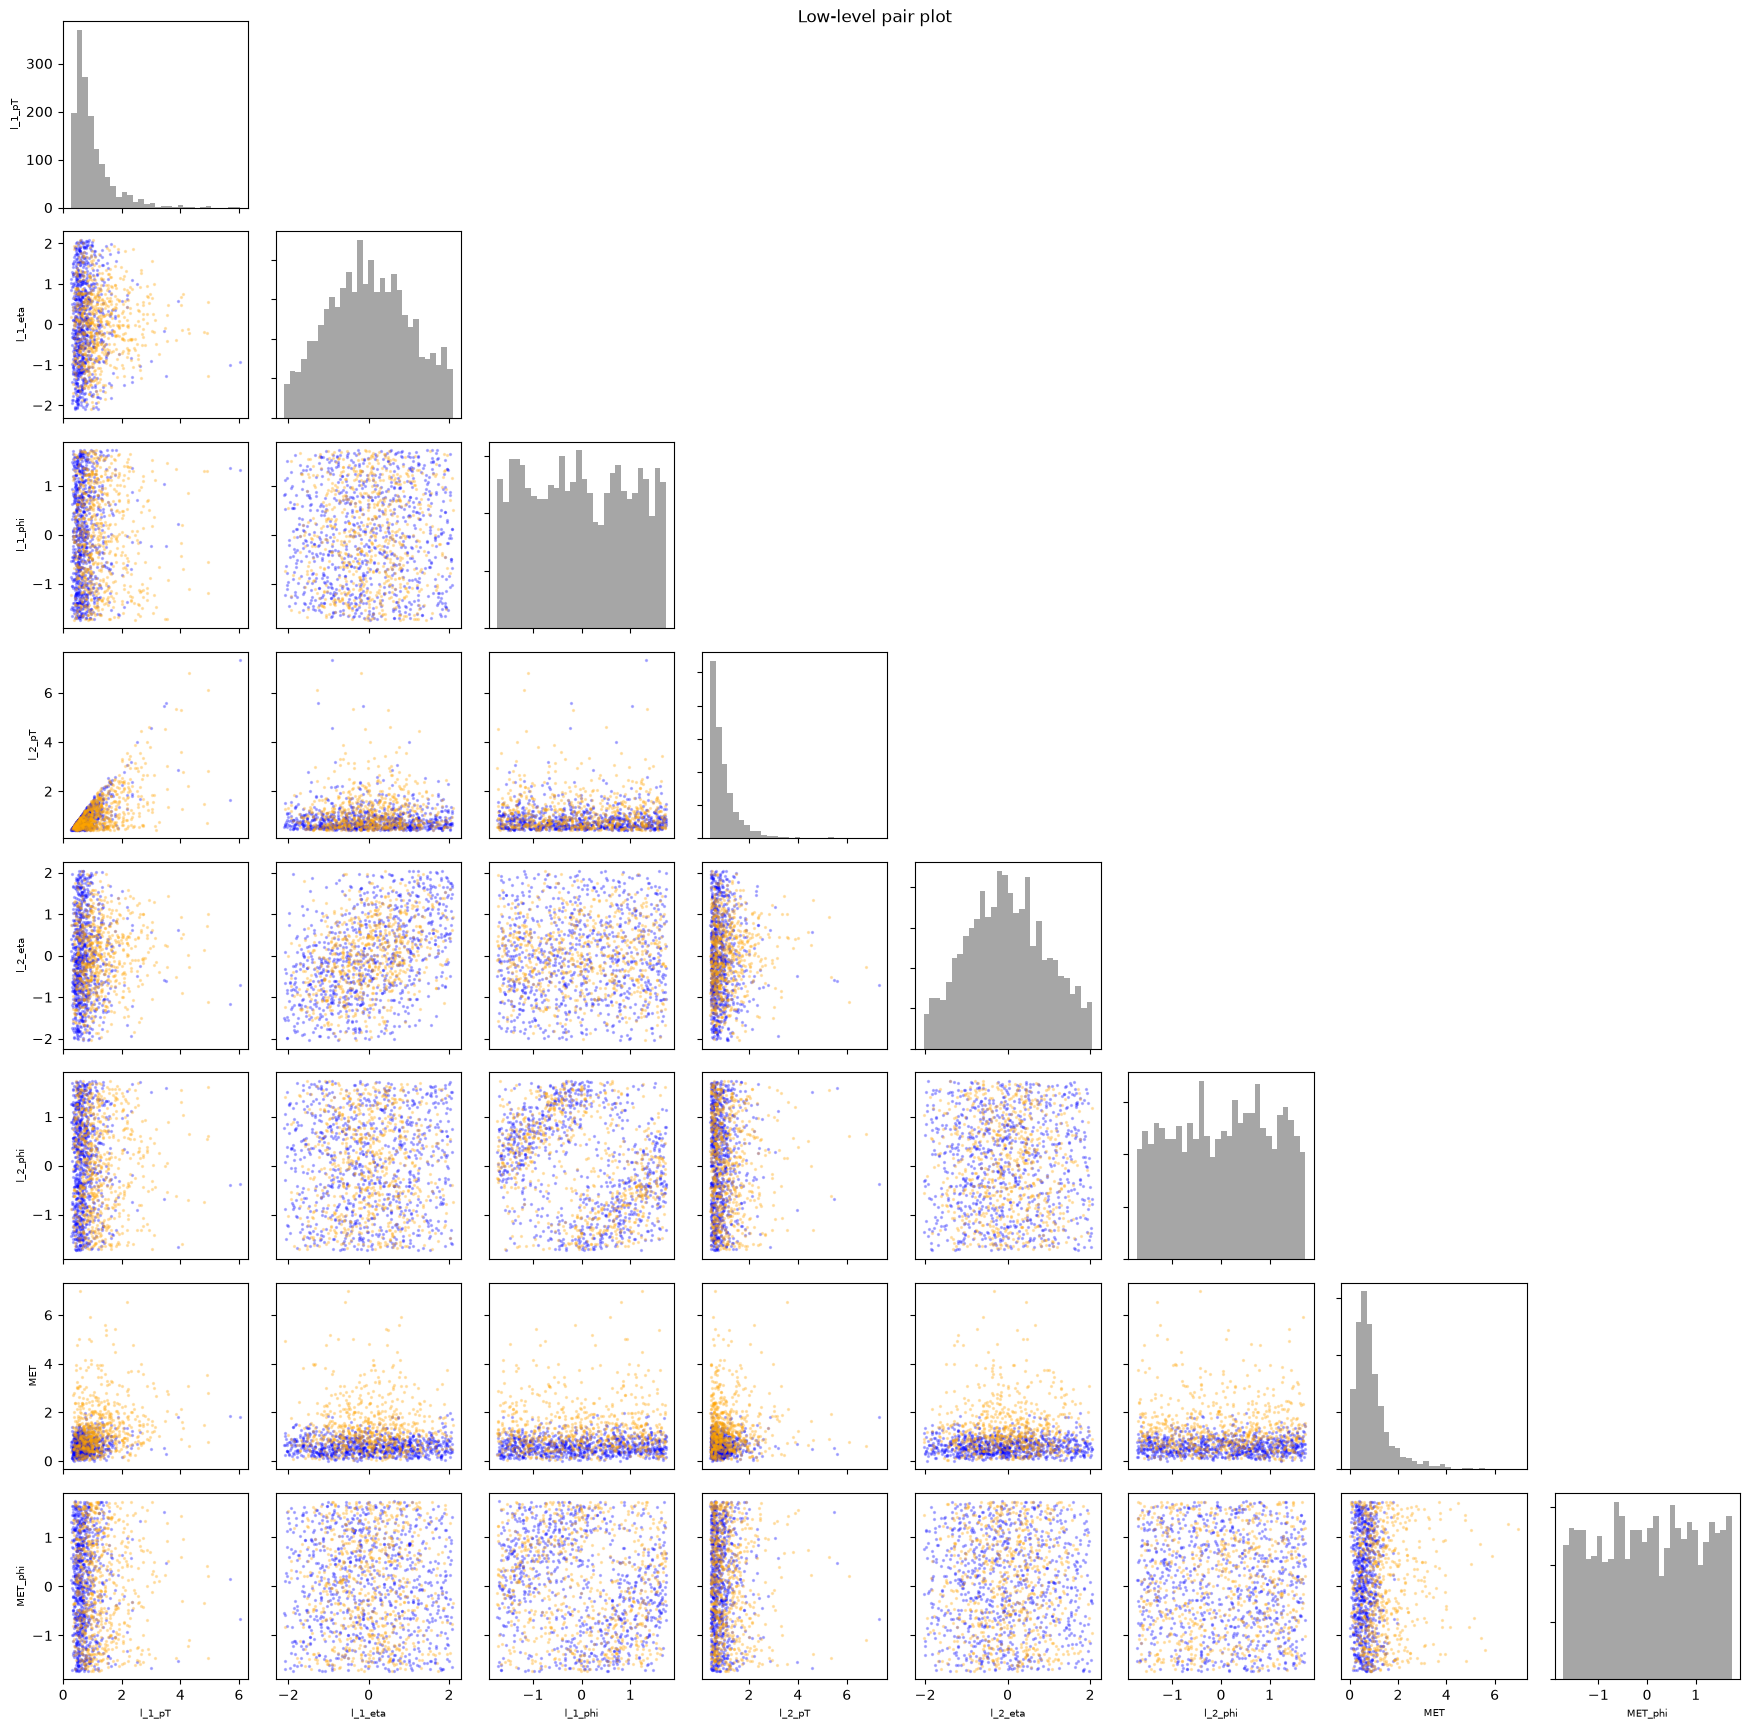

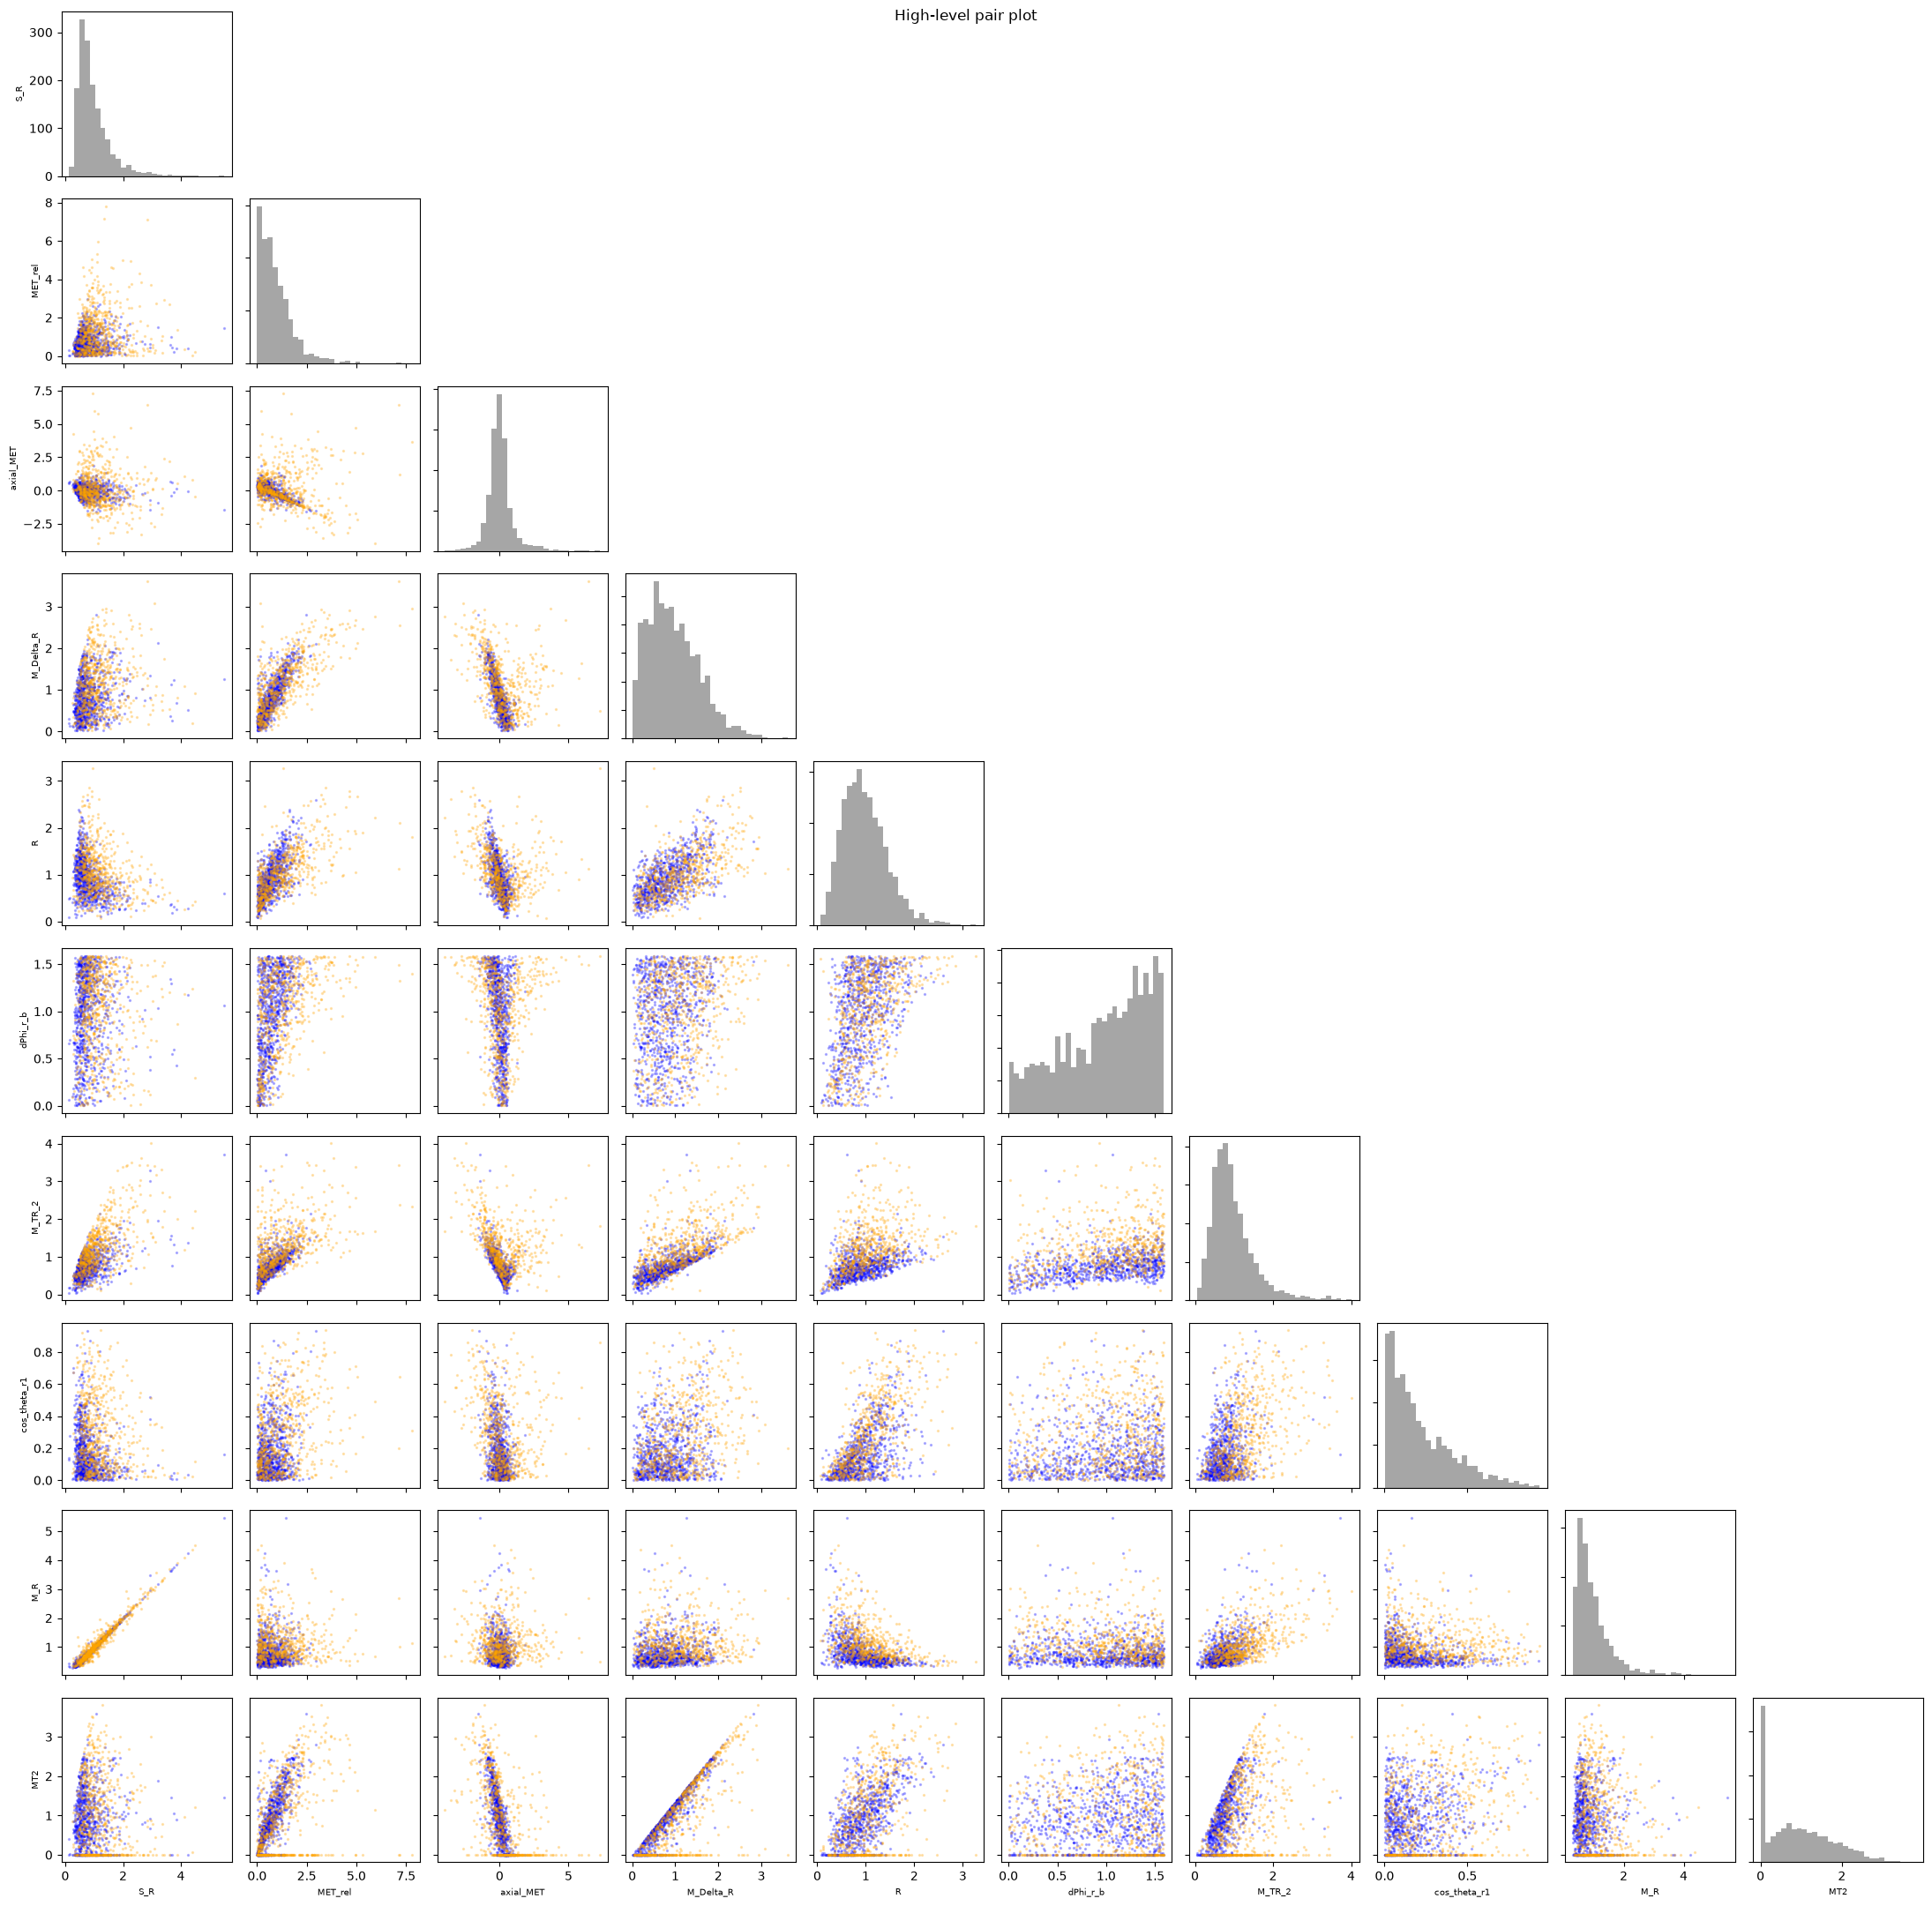

In [21]:
def pair_plot(data, columns, max_points=1500, bins=30, title=''):
    sample=data.sample(n=min(max_points,len(data)),random_state=42)
    k=len(columns)
    fig,axes=plt.subplots(k,k,figsize=(2.2*k,2.2*k))
    for i,y in enumerate(columns):
        for j,x in enumerate(columns):
            ax=axes[i,j]
            if i==j:
                ax.hist(sample[x],bins=bins,color='gray',alpha=.7)
            elif i>j:
                for cls,color in [(0,'blue'),(1,'orange')]:
                    z=sample[sample.signal==cls]
                    ax.scatter(z[x],z[y],s=2,alpha=.25,color=color,rasterized=True)
            else: ax.axis('off')
            if i==k-1:ax.set_xlabel(x,fontsize=7)
            else:ax.set_xticklabels([])
            if j==0:ax.set_ylabel(y,fontsize=7)
            else:ax.set_yticklabels([])
    fig.suptitle(title);fig.tight_layout();plt.show()

pair_plot(df,RawNames,title='Low-level pair plot')
pair_plot(df,FeatureNames,title='High-level pair plot')


### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [22]:
%pip install tabulate


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [24]:
from tabulate import tabulate
AllNames = VarNames[1:]
def show_matrices(data,columns,title=''):
    X=data[columns].to_numpy(dtype=float)
    covariance=np.cov(X,rowvar=False)
    correlation=np.corrcoef(X,rowvar=False)
    print('\n',title,'— covariance')
    display(HTML(tabulate(covariance,headers=columns,showindex=columns,
                          floatfmt='.3g',tablefmt='html')))
    print(title,'— correlation')
    display(HTML(tabulate(correlation,headers=columns,showindex=columns,
                          floatfmt='.3f',tablefmt='html')))
    return covariance,correlation

cov_all,corr_all=show_matrices(df,AllNames,'All observables')
cov_raw,corr_raw=show_matrices(df,RawNames,'Low-level observables')
cov_high,corr_high=show_matrices(df,FeatureNames,'High-level observables')


 All observables — covariance


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537


All observables — correlation


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001,0.160,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0.000,-0.001,-0.002,-0.002,0.002
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0.000,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002,-0.001,0.078,0.797,0.430,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000,0.001,-0.001,-0.001,0.000,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0.000
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003,0.704,0.176,0.264,0.720,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000,-0.005,-0.000,-0.002,-0.002,-0.000,0.000,-0.003,-0.001,-0.004,0.001
MET_rel,0.160,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1.000,-0.134,0.078,0.584,0.595,0.535,0.150,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0.000,-0.134,1.000,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272



 Low-level observables — covariance


...

,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1.000,-0.001,0.000,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1.000,-0.001,-0.000,0.406,-0.001,-0.002,-0.001
l_1_phi,0.000,-0.001,1.000,0.002,0.000,-0.266,0.001,-0.184
l_2_pT,0.684,-0.000,0.002,1.000,-0.001,0.000,0.140,-0.002
l_2_eta,-0.001,0.406,0.000,-0.001,1.000,0.000,0.000,-0.000
l_2_phi,0.001,-0.001,-0.266,0.000,0.000,1.000,-0.000,-0.035
MET,0.383,-0.002,0.001,0.140,0.000,-0.000,1.000,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0.000,-0.035,-0.003,1.000



 High-level observables — covariance


,S_R,MET_rel,axial_MET,M_Delta_R,R,dPhi_r_b,M_TR_2,cos_theta_r1,M_R,MT2
S_R,0.382,0.0823,-0.0414,0.0958,-0.0834,-0.00346,0.228,-0.0104,0.38,-0.011
MET_rel,0.0823,0.79,-0.12,0.415,0.249,0.146,0.302,0.0553,0.0437,0.409
axial_MET,-0.0414,-0.12,1.01,-0.233,-0.181,-0.0251,-0.185,-0.0537,0.0171,-0.461
M_Delta_R,0.0958,0.415,-0.233,0.389,0.165,0.0422,0.242,0.0392,0.0739,0.433
R,-0.0834,0.249,-0.181,0.165,0.222,0.0871,0.104,0.0582,-0.113,0.232
dPhi_r_b,-0.00346,0.146,-0.0251,0.0422,0.0871,0.19,0.0581,0.00908,-0.029,0.0209
M_TR_2,0.228,0.302,-0.185,0.242,0.104,0.0581,0.338,0.0517,0.21,0.189
cos_theta_r1,-0.0104,0.0553,-0.0537,0.0392,0.0582,0.00908,0.0517,0.0388,-0.0143,0.0446
M_R,0.38,0.0437,0.0171,0.0739,-0.113,-0.029,0.21,-0.0143,0.392,-0.0365
MT2,-0.011,0.409,-0.461,0.433,0.232,0.0209,0.189,0.0446,-0.0365,0.738


High-level observables — correlation


,S_R,MET_rel,axial_MET,M_Delta_R,R,dPhi_r_b,M_TR_2,cos_theta_r1,M_R,MT2
S_R,1.000,0.150,-0.067,0.249,-0.287,-0.013,0.635,-0.085,0.981,-0.021
MET_rel,0.150,1.000,-0.134,0.748,0.595,0.378,0.584,0.316,0.078,0.535
axial_MET,-0.067,-0.134,1.000,-0.373,-0.383,-0.057,-0.317,-0.272,0.027,-0.535
M_Delta_R,0.249,0.748,-0.373,1.000,0.564,0.155,0.668,0.319,0.189,0.809
R,-0.287,0.595,-0.383,0.564,1.000,0.424,0.380,0.627,-0.383,0.574
dPhi_r_b,-0.013,0.378,-0.057,0.155,0.424,1.000,0.229,0.106,-0.106,0.056
M_TR_2,0.635,0.584,-0.317,0.668,0.380,0.229,1.000,0.451,0.577,0.379
cos_theta_r1,-0.085,0.316,-0.272,0.319,0.627,0.106,0.451,1.000,-0.116,0.264
M_R,0.981,0.078,0.027,0.189,-0.383,-0.106,0.577,-0.116,1.000,-0.068
MT2,-0.021,0.535,-0.535,0.809,0.574,0.056,0.379,0.264,-0.068,1.000


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [ ]:
scenarios=[(10,100),(100,1000),(1000,10000),(10000,100000)]
def mask_cut(values,rule,cut,center=0):
    if rule=='greater':return values>cut
    if rule=='less':return values<cut
    if rule=='outside':return np.abs(values-center)>cut
    if rule=='inside':return np.abs(values-center)<cut
    raise ValueError(rule)

def candidate_cuts(values,rule,center,n=100):
    z=np.abs(values-center) if rule in ('outside','inside') else values
    return np.unique(np.quantile(z,np.linspace(.005,.995,n)))

def significance(es,eb,ns,nb):
    s=ns*es;b=nb*eb
    return np.divide(s,np.sqrt(s+b),out=np.zeros_like(np.asarray(s,dtype=float)),where=np.asarray(s+b)>0)

def cut_curves(data,col,rule,center=None,n=100):
    x=data[col].to_numpy();y=data.signal.to_numpy().astype(bool)
    if center is None:center=np.median(x)
    cuts=candidate_cuts(x,rule,center,n)
    es=np.array([np.mean(mask_cut(x[y],rule,c,center)) for c in cuts])
    eb=np.array([np.mean(mask_cut(x[~y],rule,c,center)) for c in cuts])
    return cuts,es,eb,center

rules=['greater','less','outside','inside']
selection={}
for col in AllNames:
    candidates=[]
    for rule in rules:
        cuts,es,eb,center=cut_curves(df,col,rule)
        sig=significance(es,eb,*scenarios[0])
        j=int(np.argmax(sig))
        candidates.append((float(sig[j]),rule,float(cuts[j]),float(center)))
    score,rule,cut,center=max(candidates,key=lambda t:t[0])
    selection[col]={'rule':rule,'cut':cut,'center':center,'score':score}

selection_table=pd.DataFrame([{'observable':c,**v} for c,v in selection.items()])
display(selection_table.sort_values('score',ascending=False))

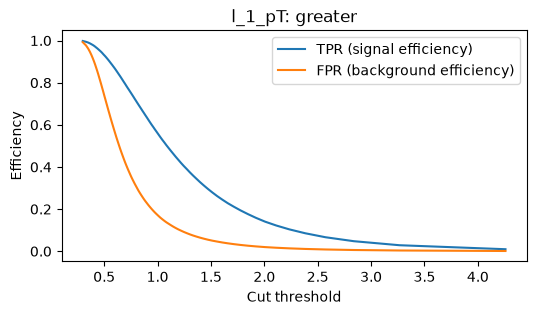

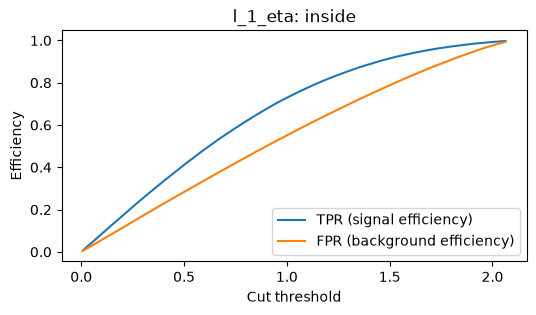

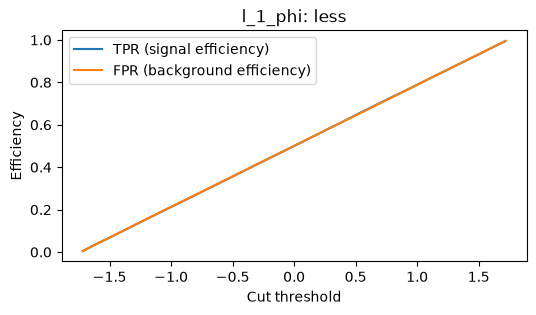

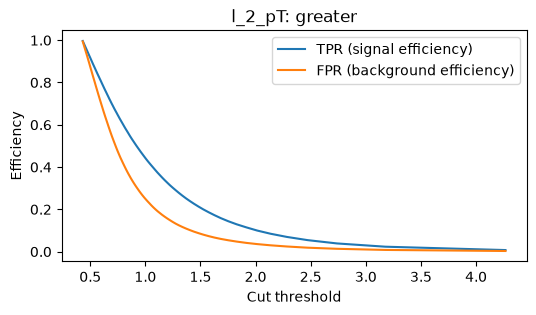

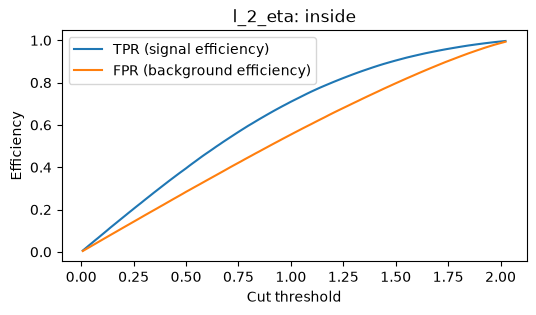

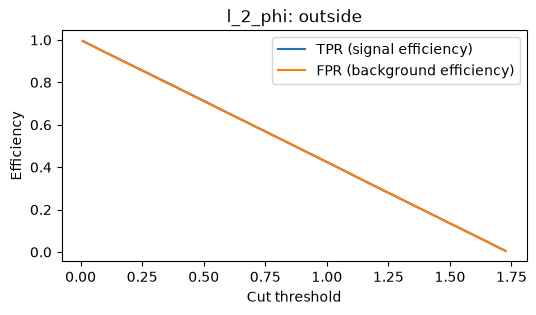

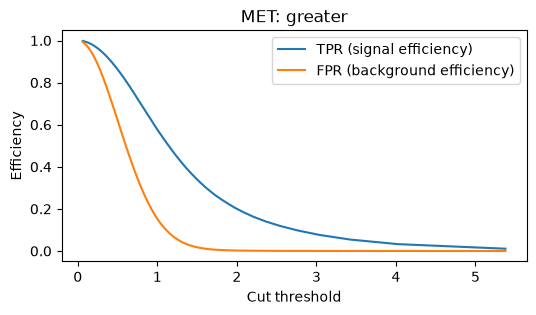

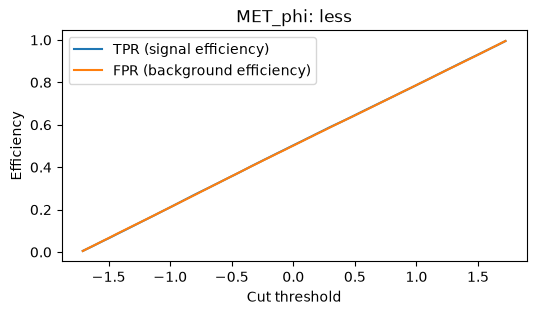

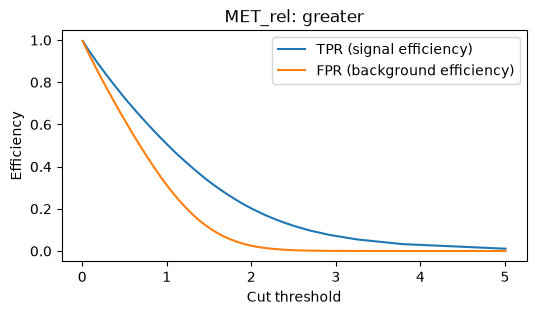

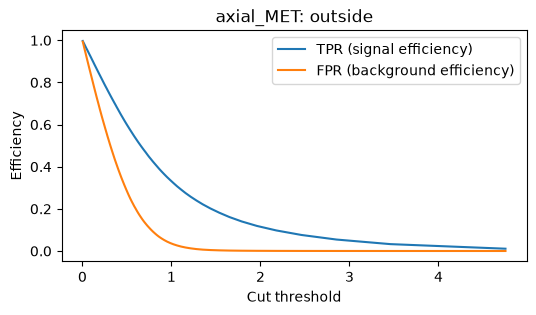

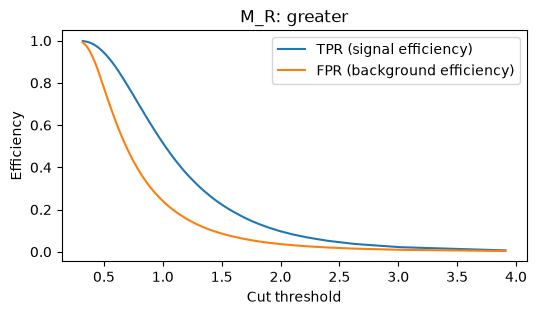

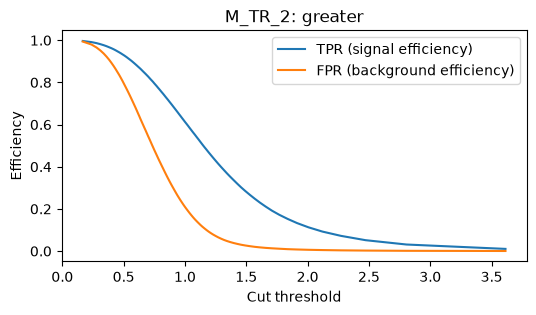

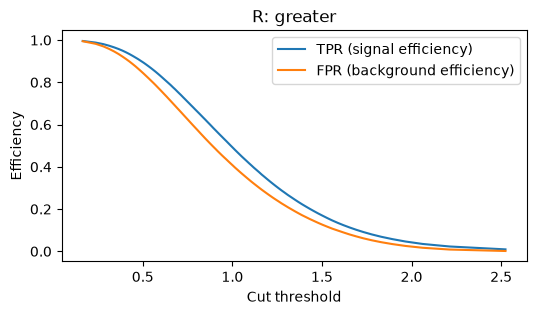

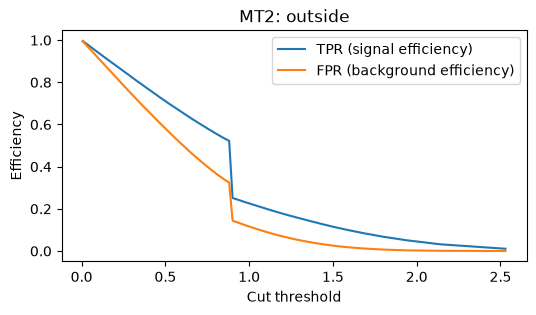

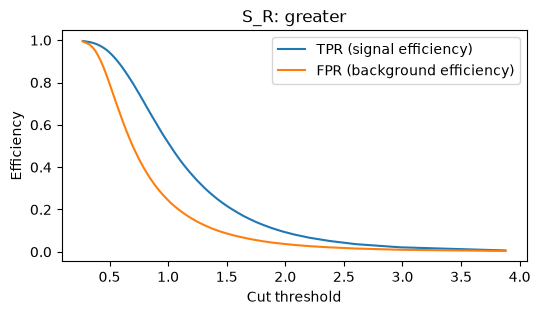

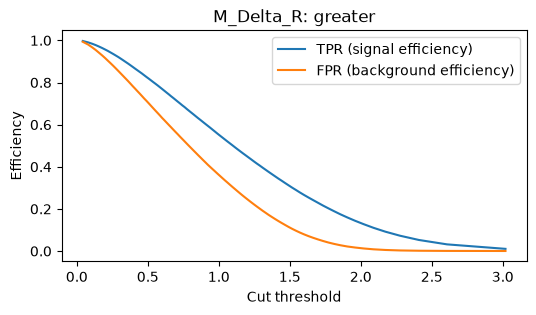

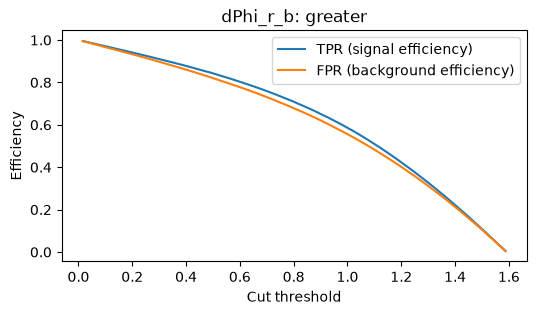

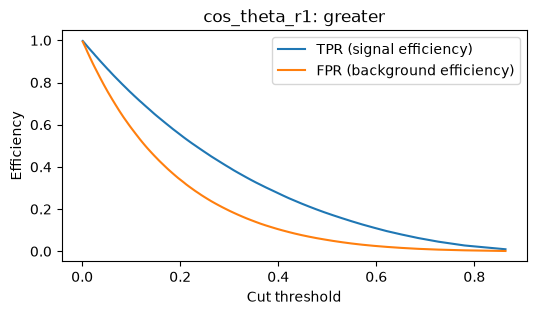

In [26]:
for col in AllNames:
    info=selection[col]
    cuts,es,eb,_=cut_curves(df,col,info['rule'],info['center'])
    fig,ax=plt.subplots(figsize=(6,3))
    ax.plot(cuts,es,label='TPR (signal efficiency)')
    ax.plot(cuts,eb,label='FPR (background efficiency)')
    ax.set(xlabel='Cut threshold',ylabel='Efficiency',title=f'{col}: {info["rule"]}')
    ax.legend();plt.show()

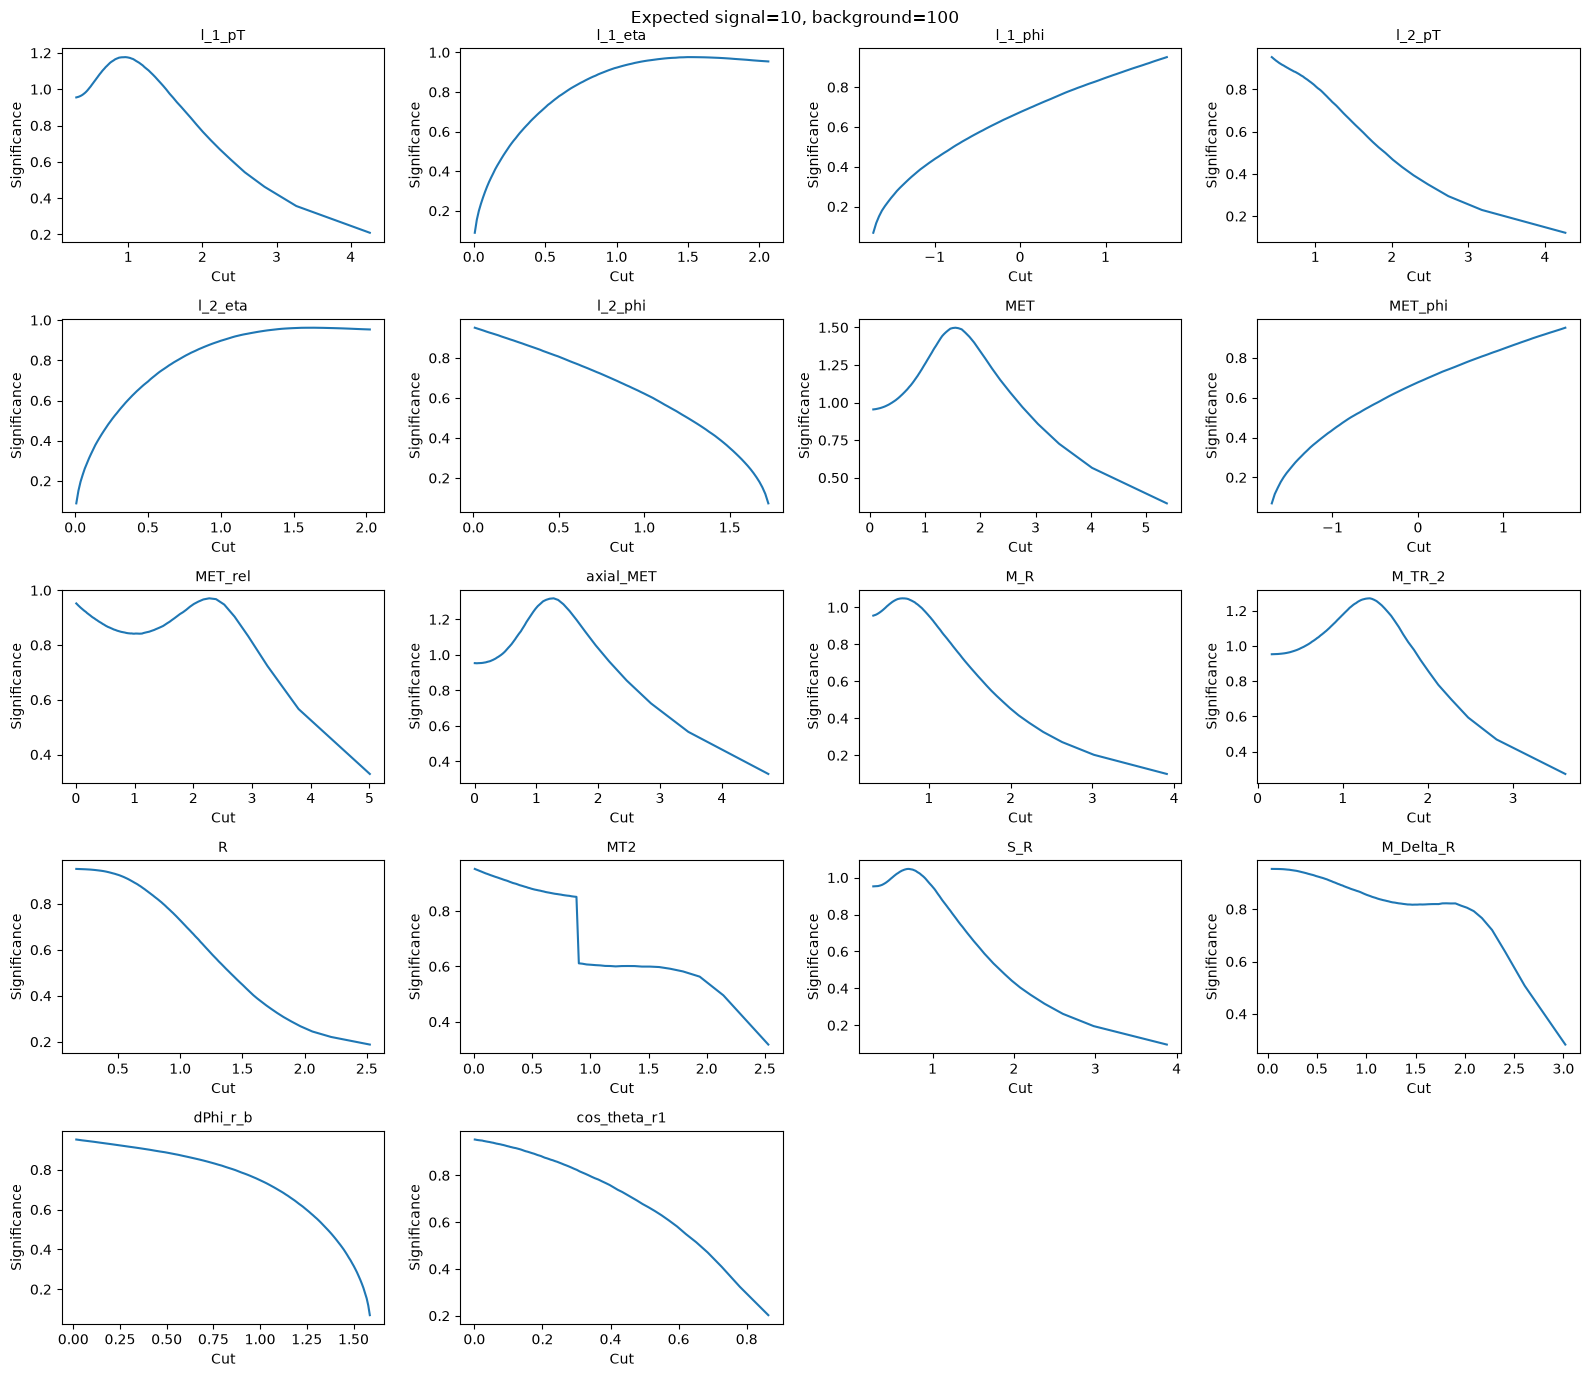

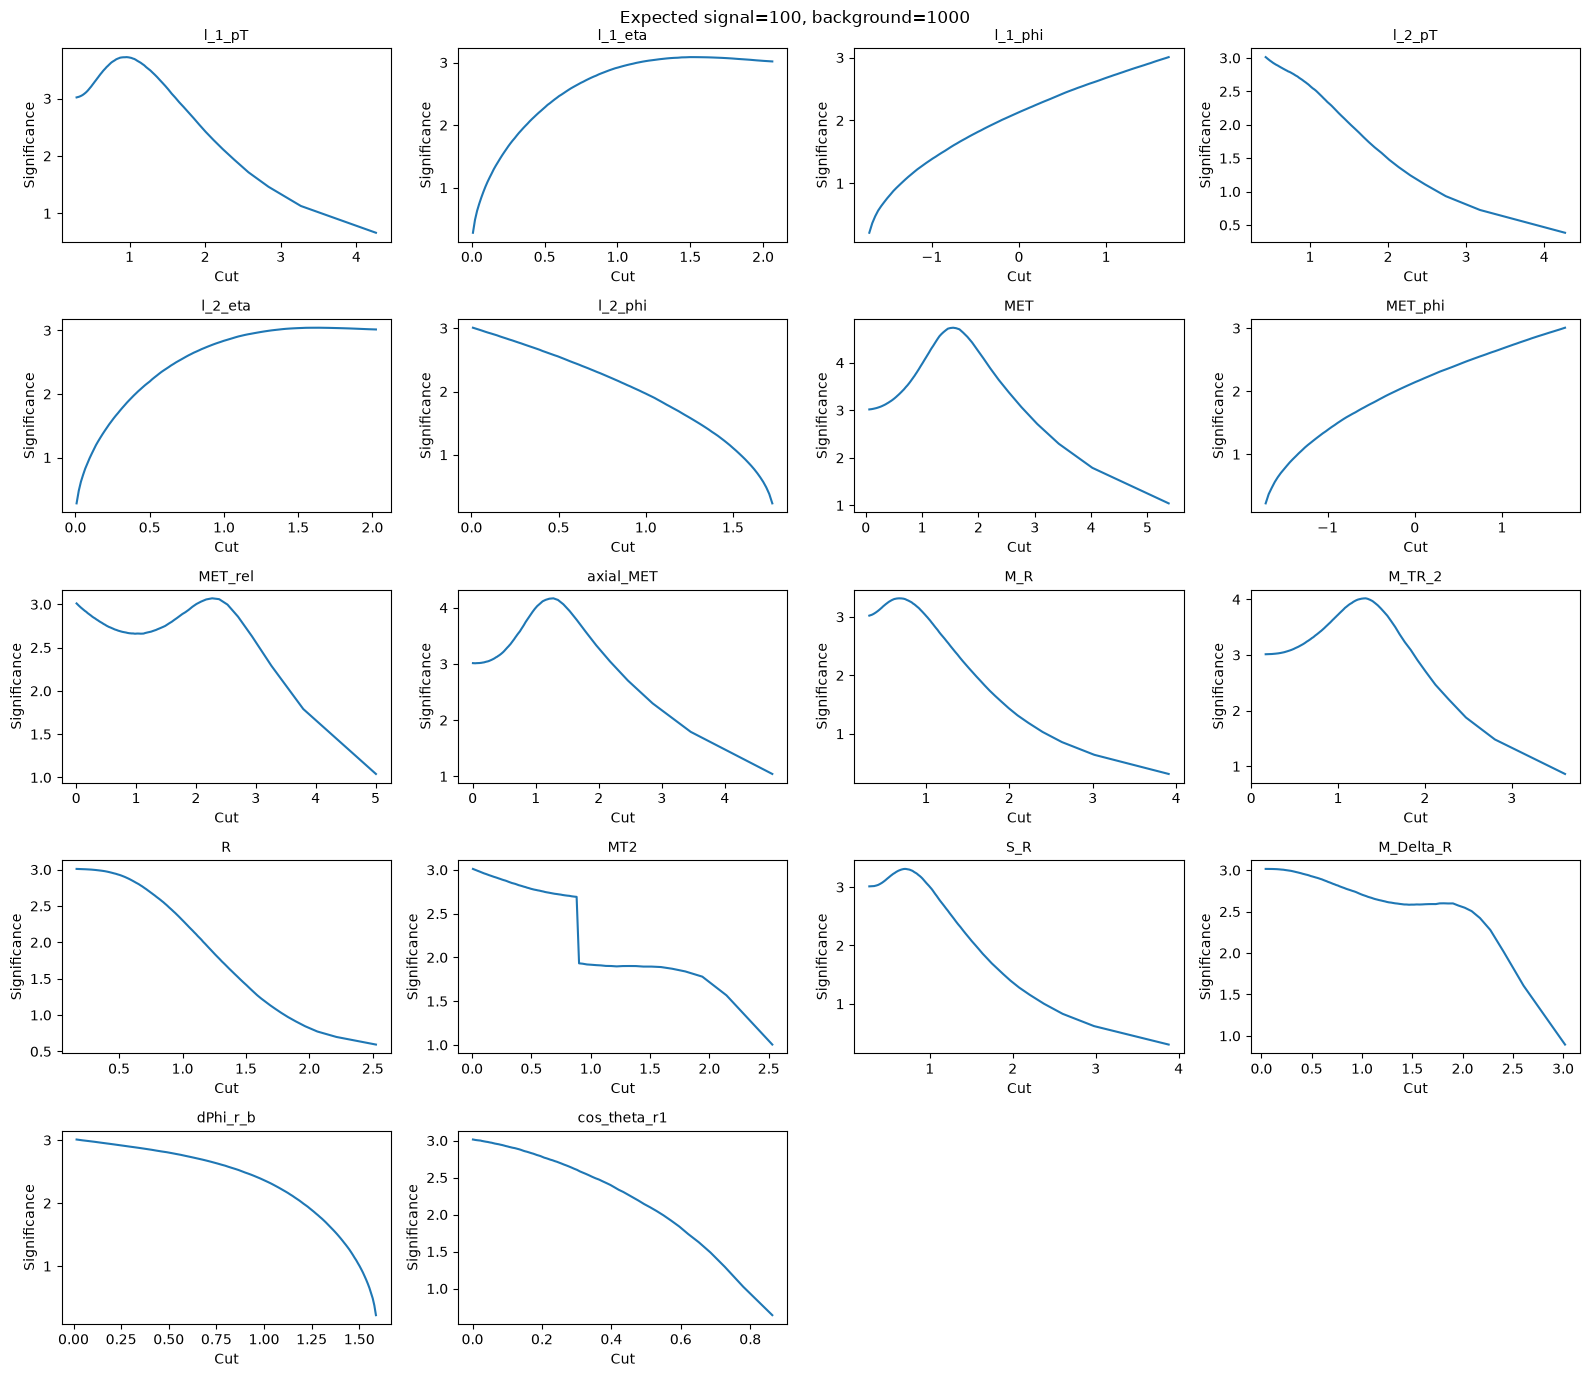

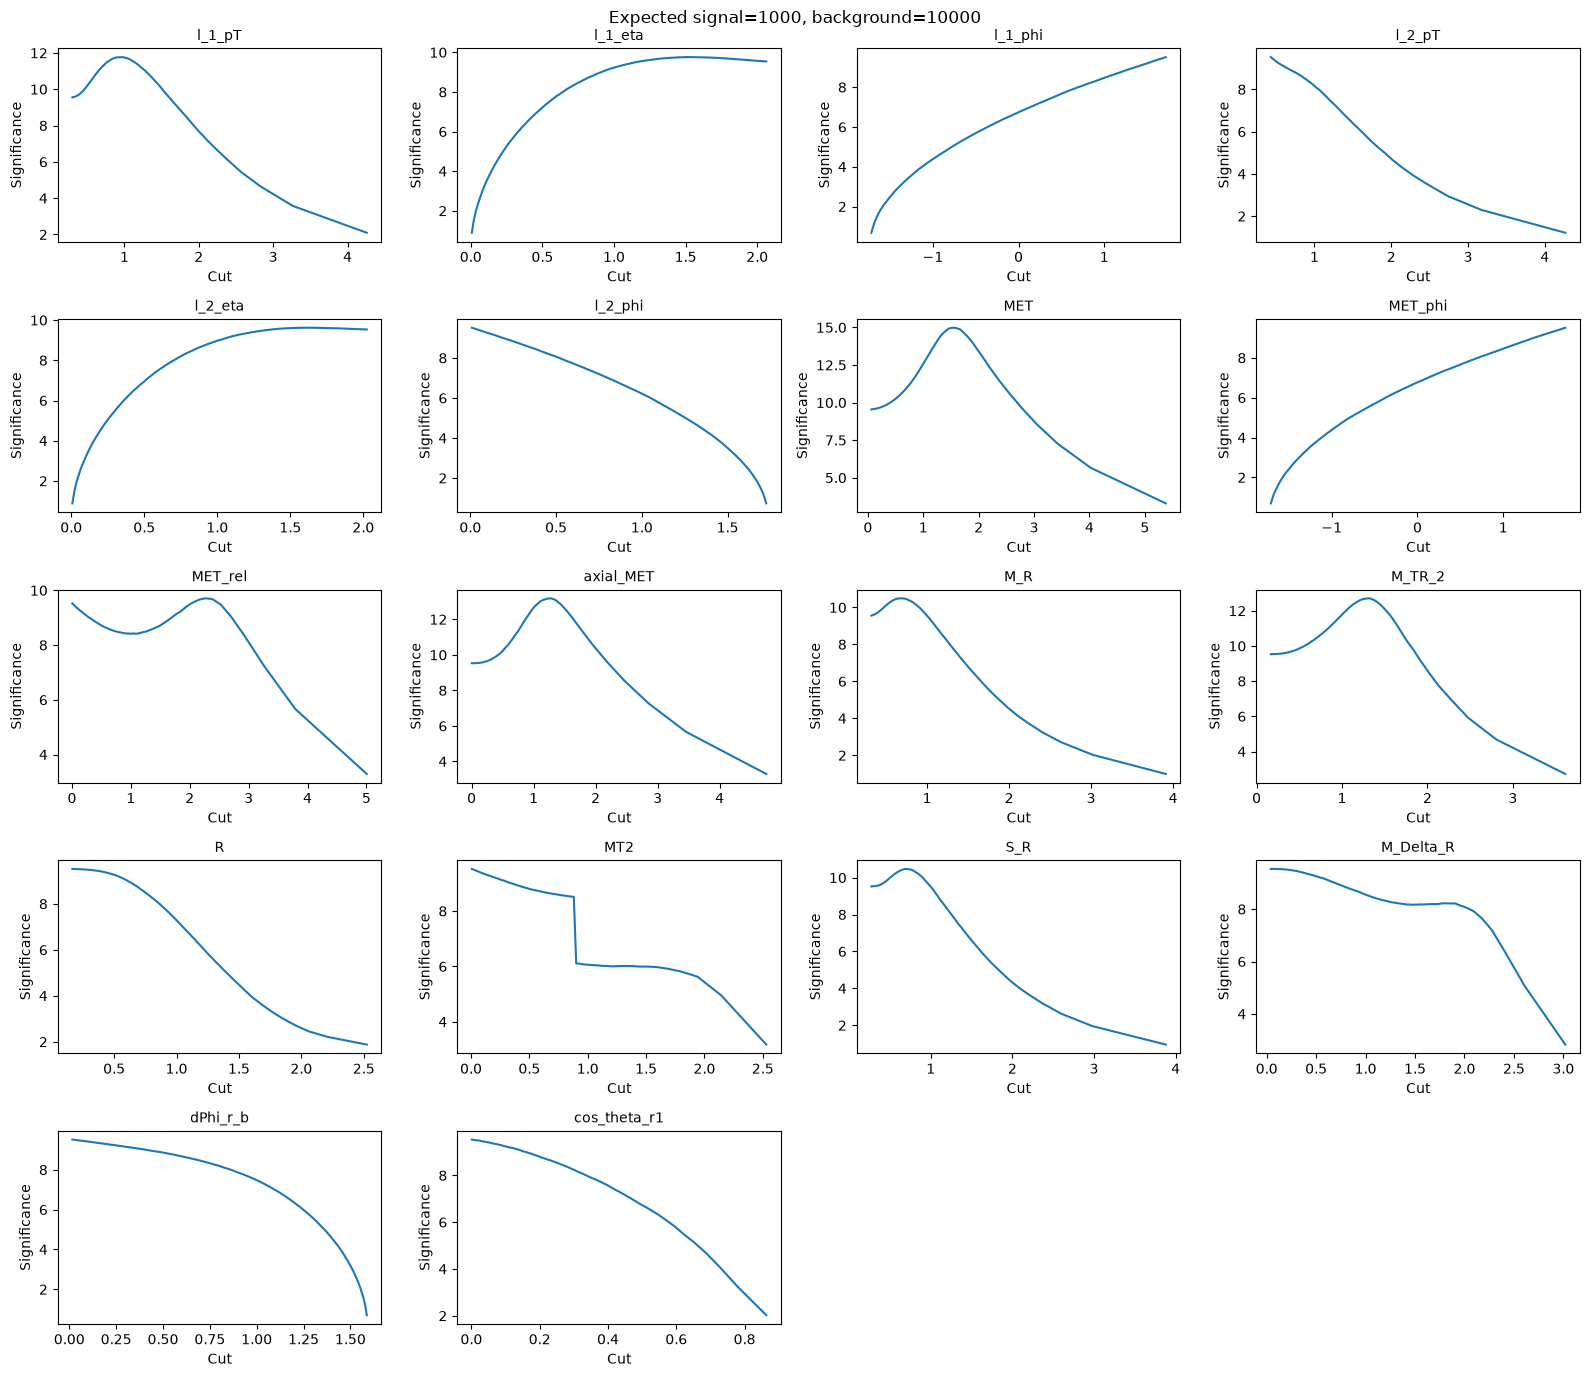

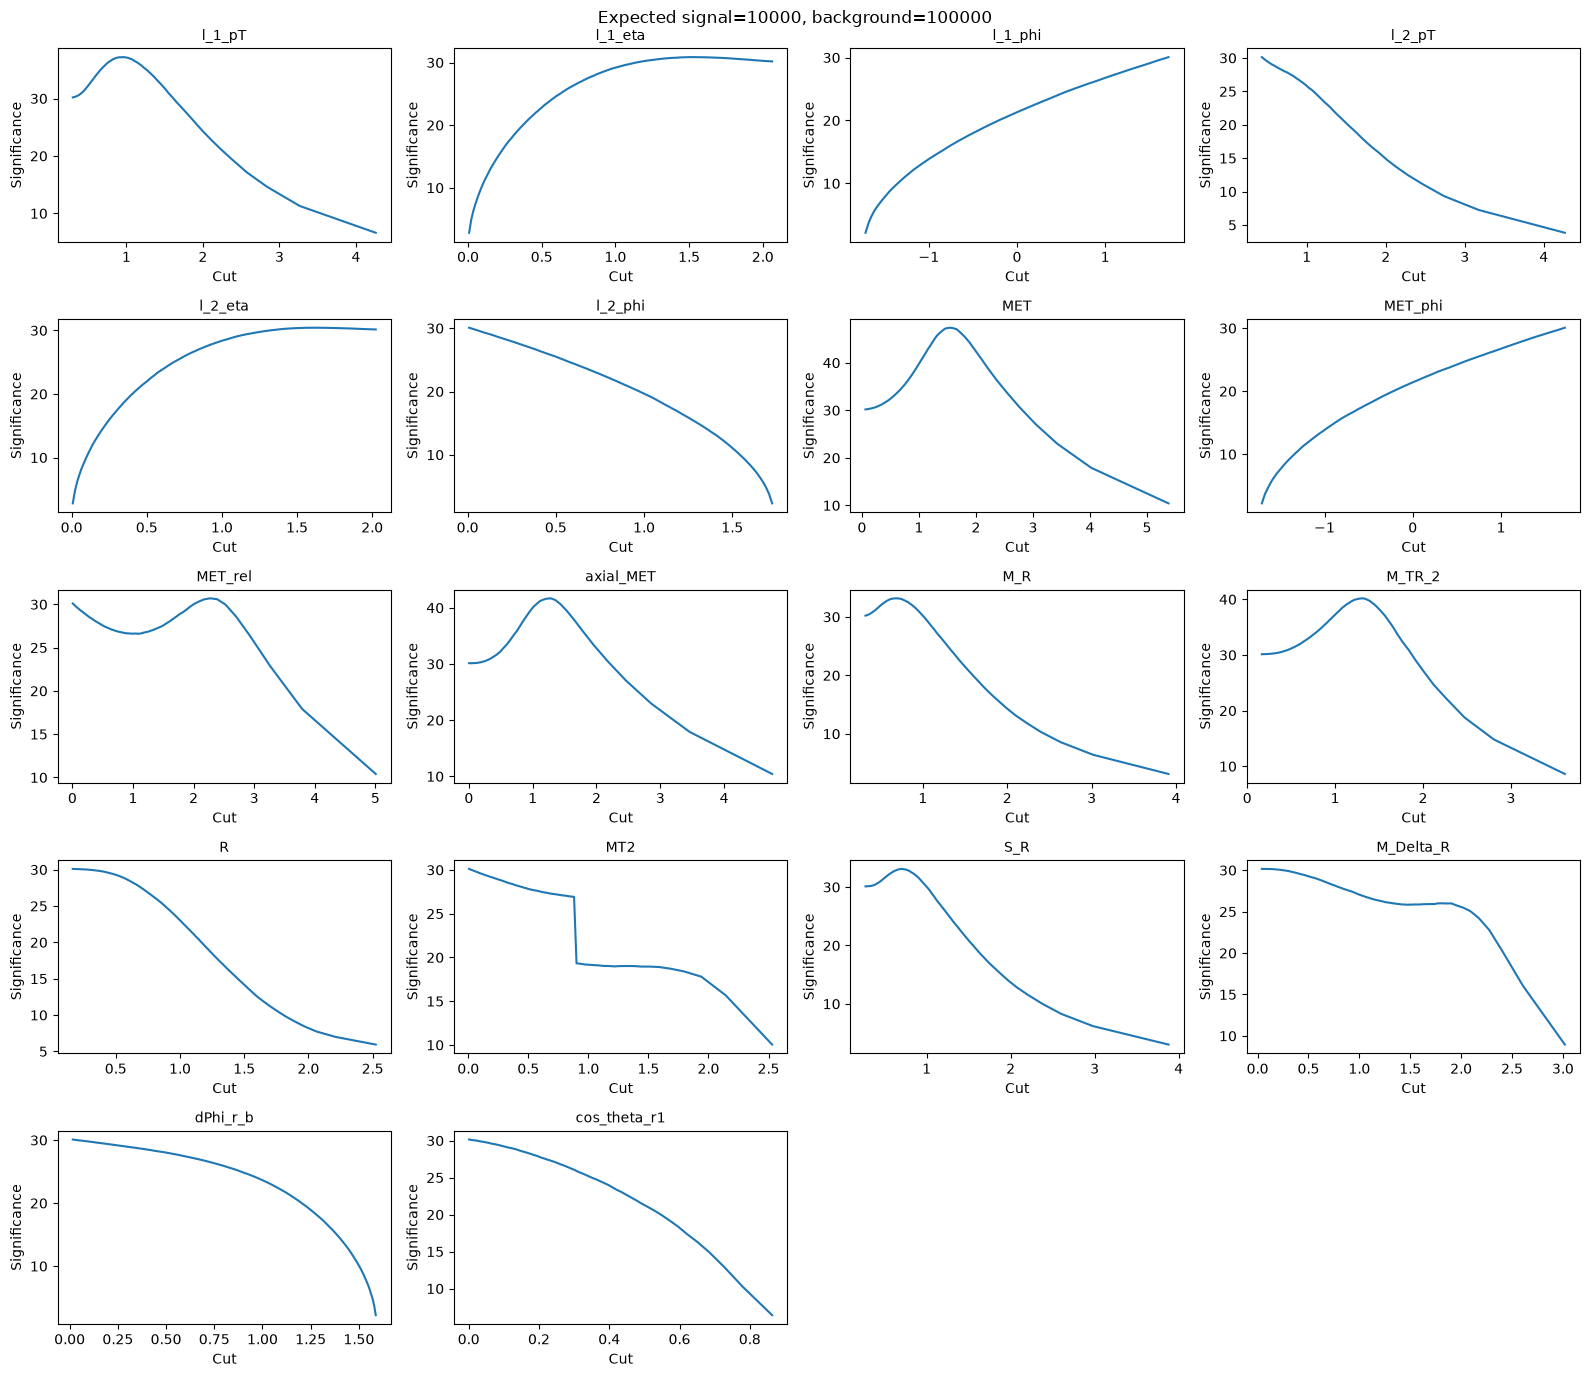

In [27]:
for ns,nb in scenarios:
    fig,axes=plt.subplots(5,4,figsize=(16,14));axes=axes.ravel()
    for ax,col in zip(axes,AllNames):
        info=selection[col]
        cuts,es,eb,_=cut_curves(df,col,info['rule'],info['center'])
        ax.plot(cuts,significance(es,eb,ns,nb))
        ax.set_title(col,fontsize=10);ax.set_xlabel('Cut');ax.set_ylabel('Significance')
    for ax in axes[len(AllNames):]:ax.axis('off')
    fig.suptitle(f'Expected signal={ns}, background={nb}')
    fig.tight_layout();plt.show()

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [28]:
top3=selection_table.sort_values('score',ascending=False).head(3)['observable'].tolist()
print('Selected observables:',top3)

def apply_selection(data,col,info):
    return mask_cut(data[col].to_numpy(),info['rule'],info['cut'],info['center'])

def cutflow(data,variables,settings,ns,nb):
    keep=np.ones(len(data),dtype=bool)
    sig=data.signal.to_numpy().astype(bool)
    rows=[]
    for col in variables:
        keep &= apply_selection(data,col,settings[col])
        es=np.mean(keep[sig]);eb=np.mean(keep[~sig])
        rows.append({'cut':col,'epsilon_S':es,'epsilon_B':eb,
                     "N'_S":ns*es,"N'_B":nb*eb,'significance':float(significance(es,eb,ns,nb))})
    return pd.DataFrame(rows)

for ns,nb in scenarios:
    print(f'Cut flow: NS={ns}, NB={nb}')
    display(cutflow(df,top3,selection,ns,nb).round(4))

Selected observables: ['MET', 'axial_MET', 'M_TR_2']
Cut flow: NS=10, NB=100


,cut,epsilon_S,epsilon_B,N'_S,N'_B,significance
0,MET,0.3216,0.0139,3.2161,1.3931,1.4980
1,axial_MET,0.2057,0.0051,2.0573,0.5082,1.2844
2,M_TR_2,0.1403,0.0044,1.4033,0.4432,1.0327


Cut flow: NS=100, NB=1000


,cut,epsilon_S,epsilon_B,N'_S,N'_B,significance
0,MET,0.3216,0.0139,32.1612,13.9314,4.7371
1,axial_MET,0.2057,0.0051,20.5727,5.0821,4.0617
2,M_TR_2,0.1403,0.0044,14.0330,4.4321,3.2657


Cut flow: NS=1000, NB=10000


,cut,epsilon_S,epsilon_B,N'_S,N'_B,significance
0,MET,0.3216,0.0139,321.6122,139.3141,14.9802
1,axial_MET,0.2057,0.0051,205.7275,50.8209,12.8442
2,M_TR_2,0.1403,0.0044,140.3302,44.3205,10.3270


Cut flow: NS=10000, NB=100000


,cut,epsilon_S,epsilon_B,N'_S,N'_B,significance
0,MET,0.3216,0.0139,3216.1225,1393.1414,47.3715
1,axial_MET,0.2057,0.0051,2057.2750,508.2085,40.6170
2,M_TR_2,0.1403,0.0044,1403.3021,443.2051,32.6570


In [29]:
candidates=selection_table.sort_values('score',ascending=False).head(8)['observable'].tolist()
pairs=[(abs(float(corr_all[AllNames.index(a),AllNames.index(b)])),a,b)
       for i,a in enumerate(candidates) for b in candidates[i+1:]]
_,var1,var2=max(pairs)
print('Pair with strongest absolute correlation among top 8:',var1,var2)

def optimize_second(first,second,ns=1000,nb=10000):
    first_mask=apply_selection(df,first,selection[first])
    signal=df.signal.to_numpy().astype(bool)
    second_vals=df[second].to_numpy()
    center=selection[second]['center']
    best=None
    for rule in rules:
        for cut in candidate_cuts(second_vals,rule,center,80):
            keep=first_mask & mask_cut(second_vals,rule,cut,center)
            es=np.mean(keep[signal]);eb=np.mean(keep[~signal])
            score=float(significance(es,eb,ns,nb))
            if best is None or score>best[0]:best=(score,rule,float(cut),es,eb)
    return {'first':first,'second':second,'significance':best[0],
            'second_rule':best[1],'second_cut':best[2],
            'epsilon_S':best[3],'epsilon_B':best[4]}

forward=optimize_second(var1,var2)
reverse=optimize_second(var2,var1)
display(pd.DataFrame([forward,reverse]))
print('Order changes the conditional optimization because the first cut is fixed and the second is optimized afterward.')

Pair with strongest absolute correlation among top 8: M_R S_R


,first,second,significance,second_rule,second_cut,epsilon_S,epsilon_B
0,M_R,S_R,10.480542,greater,0.271722,0.804685,0.509032
1,S_R,M_R,10.470831,greater,0.320174,0.787734,0.487201


Order changes the conditional optimization because the first cut is fixed and the second is optimized afterward.


## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



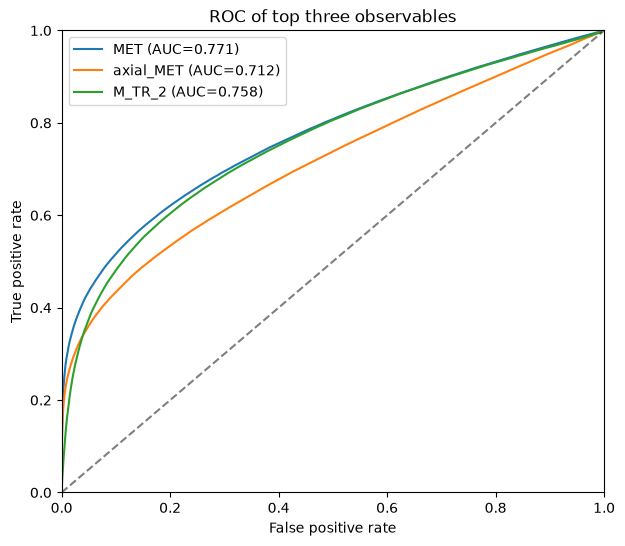

AUC values: {'MET': 0.7709575376442391, 'axial_MET': 0.7123111434330307, 'M_TR_2': 0.7581760859922765}


In [31]:
def auc_curve(fpr,tpr):
    order=np.argsort(fpr)
    x=np.r_[0,np.asarray(fpr)[order],1]
    y=np.r_[0,np.asarray(tpr)[order],1]
    u=np.unique(x)
    v=np.array([np.max(y[x==z]) for z in u])
    return float(np.trapezoid(v,u))

def plot_roc(data,columns,settings=None,title='ROC curves',base_mask=None):
    if settings is None:settings=selection
    y=data.signal.to_numpy().astype(bool)
    if base_mask is None:base_mask=np.ones(len(data),dtype=bool)
    fig,ax=plt.subplots(figsize=(7,6))
    out={}
    for col in columns:
        info=settings[col]
        cuts,_,_,_=cut_curves(data,col,info['rule'],info['center'],150)
        x=data[col].to_numpy()
        es=[];eb=[]
        for cut in cuts:
            keep=base_mask & mask_cut(x,info['rule'],cut,info['center'])
            es.append(np.mean(keep[y]));eb.append(np.mean(keep[~y]))
        area=auc_curve(eb,es)
        out[col]=area
        ax.plot(eb,es,label=f'{col} (AUC={area:.3f})')
    ax.plot([0,1],[0,1],'k--',alpha=.5)
    ax.set(xlabel='False positive rate',ylabel='True positive rate',title=title,
           xlim=(0,1),ylim=(0,1));ax.legend();plt.show()
    return out

# 7.1 and 7.2
auc_results=plot_roc(df,top3,title='ROC of top three observables')
print('AUC values:',auc_results)

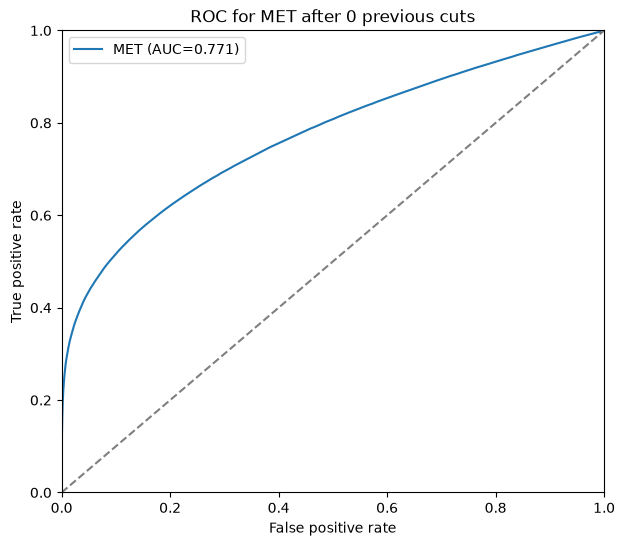

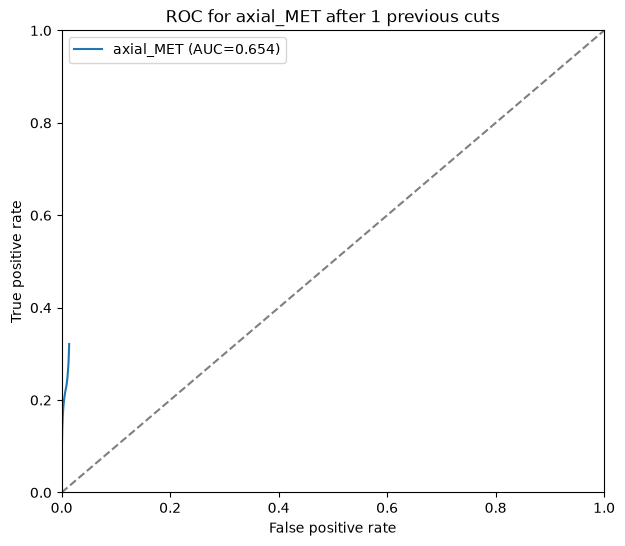

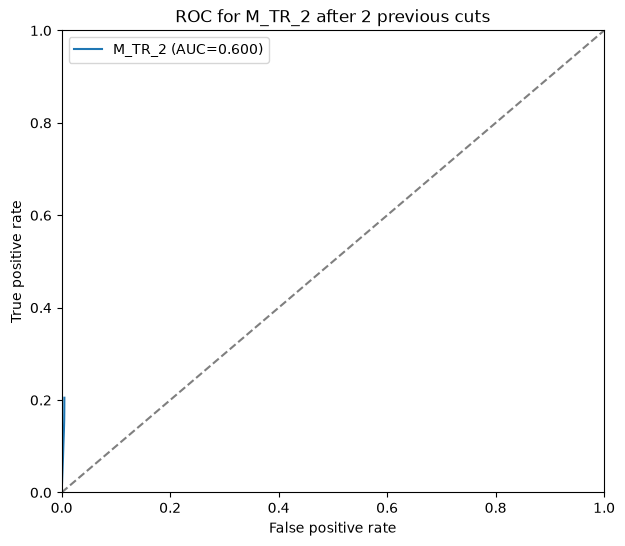

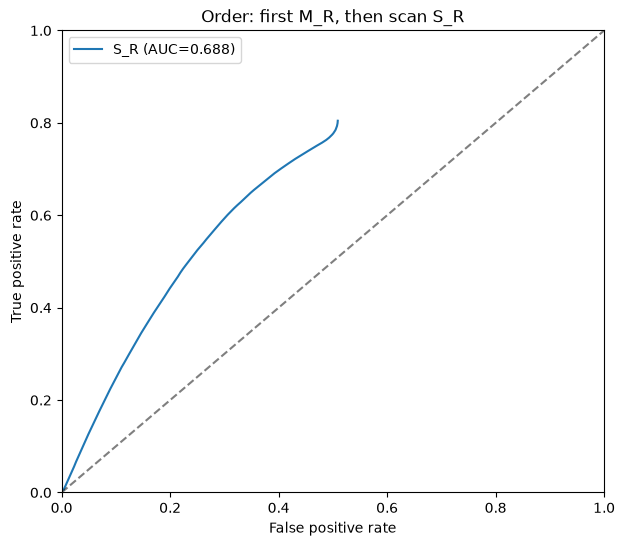

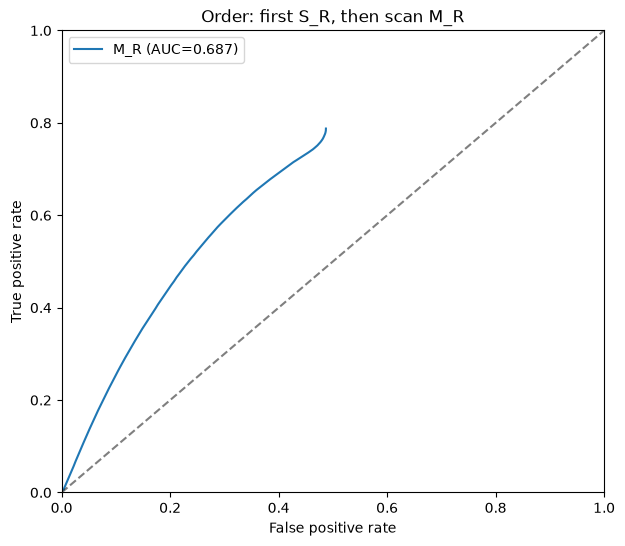

In [32]:
# 7.3
for k in range(len(top3)):
    base=np.ones(len(df),dtype=bool)
    for previous in top3[:k]:base &= apply_selection(df,previous,selection[previous])
    plot_roc(df,[top3[k]],title=f'ROC for {top3[k]} after {k} previous cuts',base_mask=base)

# 7.4
for first,second in [(var1,var2),(var2,var1)]:
    base=apply_selection(df,first,selection[first])
    plot_roc(df,[second],title=f'Order: first {first}, then scan {second}',base_mask=base)

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

S_B shape: (18, 18) S_W shape: (18, 18)
Fisher coefficients (standardized features):


,observable,coefficient
0,l_1_pT,1.550916e-06
1,l_1_eta,5.648989e-09
2,l_1_phi,2.108413e-09
3,l_2_pT,6.494142e-07
4,l_2_eta,3.495416e-09
5,l_2_phi,2.712761e-09
6,MET,1.442180e-06
7,MET_phi,2.746955e-09
8,MET_rel,1.242271e-07
9,axial_MET,2.649144e-07


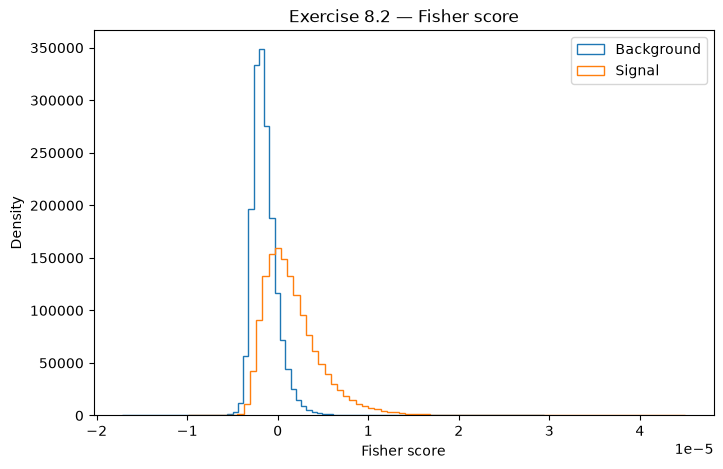

In [33]:
X=df[AllNames].to_numpy(dtype=float)
y=df.signal.to_numpy().astype(bool)
mu=X.mean(axis=0);sd=X.std(axis=0);sd[sd==0]=1
Z=(X-mu)/sd
Z_sig=Z[y];Z_bkg=Z[~y]
m_sig=Z_sig.mean(axis=0);m_bkg=Z_bkg.mean(axis=0)
delta=(m_sig-m_bkg).reshape(-1,1)
S_B=delta@delta.T
C_sig=Z_sig-m_sig;C_bkg=Z_bkg-m_bkg
S_W=C_sig.T@C_sig+C_bkg.T@C_bkg
w=np.linalg.pinv(S_W)@(m_sig-m_bkg)
score=Z@w
if score[y].mean()<score[~y].mean():
    w=-w;score=-score
print('S_B shape:',S_B.shape,'S_W shape:',S_W.shape)
print('Fisher coefficients (standardized features):')
display(pd.DataFrame({'observable':AllNames,'coefficient':w}))
plt.figure(figsize=(8,5))
plt.hist(score[~y],bins=80,density=True,histtype='step',label='Background')
plt.hist(score[y],bins=80,density=True,histtype='step',label='Signal')
plt.xlabel('Fisher score');plt.ylabel('Density');plt.title('Exercise 8.2 — Fisher score');plt.legend();plt.show()

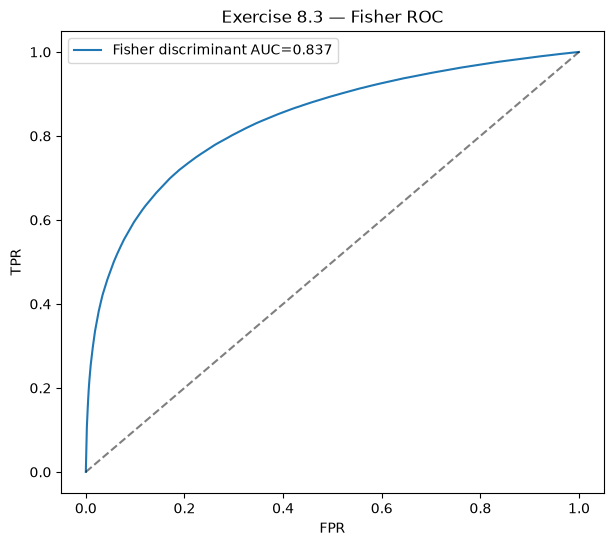

Exercise 8.4 — maximal significance by scenario


,N_S,N_B,maximum_significance,optimal_Fisher_cut,signal_efficiency,background_efficiency
0,10,100,1.532048,0.000001,0.471605,0.047597
1,100,1000,4.844761,0.000001,0.471605,0.047597
2,1000,10000,15.320481,0.000001,0.471605,0.047597
3,10000,100000,48.447615,0.000001,0.471605,0.047597


In [34]:
# 8.3 and 8.4
thresholds=np.unique(np.quantile(score,np.linspace(0,1,501)))
tpr=np.array([np.mean(score[y]>t) for t in thresholds])
fpr=np.array([np.mean(score[~y]>t) for t in thresholds])
auc=auc_curve(fpr,tpr)
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,label=f'Fisher discriminant AUC={auc:.3f}')
plt.plot([0,1],[0,1],'k--',alpha=.5)
plt.xlabel('FPR');plt.ylabel('TPR');plt.title('Exercise 8.3 — Fisher ROC');plt.legend();plt.show()

rows=[]
for ns,nb in scenarios:
    sig=significance(tpr,fpr,ns,nb)
    j=int(np.argmax(sig))
    rows.append({'N_S':ns,'N_B':nb,'maximum_significance':float(sig[j]),
                 'optimal_Fisher_cut':float(thresholds[j]),
                 'signal_efficiency':float(tpr[j]),'background_efficiency':float(fpr[j])})
print('Exercise 8.4 — maximal significance by scenario')
display(pd.DataFrame(rows))